# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Іванів Христина'      # прізвище та ім'я
GROUP        = 'ШІ-24'      # шифр групи, наприклад СШІ-31
NUMBER       = 4      # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Іванів Христина | ШІ-24 | номер 4


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 4   ·   Іванів Христина   ·   ШІ-24

   Ринок:  Kherson
   Товар:  сметана   (у наборі даних: Sour cream - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | 28.10.2026|
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('ціни_україна_2014_2017.csv', encoding='utf-8')

# ряд свого варіанта
s = df[(df['ринок'] == MARKET) & (df['товар'] == GOOD)].copy()
s['date'] = pd.to_datetime(dict(year=s['рік'], month=s['місяць'], day=1))
s = s.set_index('date')['ціна'].sort_index()

# повна місячна сітка 03.2014 – 12.2017 (MS = перше число місяця)
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
y = s.reindex(grid)
y.index.name = 'date'

print(f'Місяців у сітці: {len(y)}')
print(f'Мають вимір:     {y.notna().sum()}')
print(f'Пропусків:       {y.isna().sum()}')
print('Пропущені місяці:', [d.strftime('%Y-%m') for d in y[y.isna()].index])

# чи пропуск специфічний для мого ряду, чи для всього набору?
df['date'] = pd.to_datetime(dict(year=df['рік'], month=df['місяць'], day=1))
per_month = df.groupby('date').size().reindex(grid, fill_value=0)
print('\nМісяці, у яких у ВСЬОМУ наборі немає жодного запису:',
      [d.strftime('%Y-%m') for d in per_month[per_month == 0].index])

# ряди, де є пропуск 08.2017 (усі ринки/товари з даними за 2017 рік)
has_2017 = df[df['рік'] == 2017].groupby(['ринок', 'товар']).size()
print(f'Рядів із даними у 2017 році: {len(has_2017)}; '
      f'з них мають запис за 08.2017: '
      f'{len(df[(df["рік"]==2017)&(df["місяць"]==8)])}')

y.head()

Місяців у сітці: 46
Мають вимір:     45
Пропусків:       1
Пропущені місяці: ['2017-08']

Місяці, у яких у ВСЬОМУ наборі немає жодного запису: ['2017-08']
Рядів із даними у 2017 році: 650; з них мають запис за 08.2017: 0


date
2014-03-01    21.6667
2014-04-01    21.2533
2014-05-01    21.7300
2014-06-01    21.8600
2014-07-01    21.8000
Freq: MS, Name: ціна, dtype: float64

**Висновок до завдання 1:**

Ряд "сметана – Kherson" після приведення до повної місячної сітки 03.2014–12.2017 містить 46 місяців, з них 45 мають вимір. Пропуск один — серпень 2017 року. Він не стосується лише мого ряду: у всьому наборі за 08.2017 немає жодного запису по жодному ринку й товару. Отже, це прогалина в зборі або публікації даних (місяць просто не потрапив у джерело), а не зникнення товару з продажу чи особливість ринку. Інших пропусків у ряді немає, тож ряд регулярний, і після заповнення одного значення його можна аналізувати як рівномірний місячний часовий ряд.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

Сусіди пропуску: 07.2017 = 44.5400, 09.2017 = 44.2067

Перенесення останнього (ffill)    44.5400
Лінійна інтерполяція              44.3734
Перенесення наступного (bfill)    44.2067


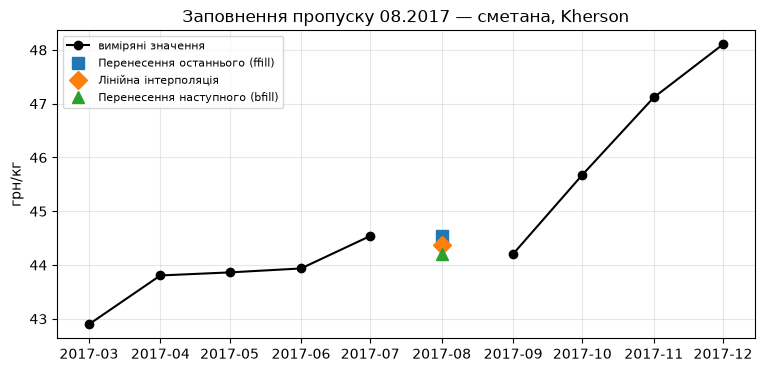


Після заповнення: 46 місяців, пропусків — 0


In [4]:
gap = pd.Timestamp('2017-08-01')

fills = {
    'Перенесення останнього (ffill)':  y.ffill(),
    'Лінійна інтерполяція':            y.interpolate(method='linear'),
    'Перенесення наступного (bfill)':  y.bfill(),
}

print(f"Сусіди пропуску: 07.2017 = {y['2017-07-01']:.4f}, 09.2017 = {y['2017-09-01']:.4f}\n")
res = pd.Series({k: v[gap] for k, v in fills.items()}, name='значення за 08.2017')
print(res.round(4).to_string())

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))
win = slice('2017-03-01', '2017-12-01')
ax.plot(y[win].index, y[win].values, 'ko-', label='виміряні значення', zorder=3)
for (name, ser), m in zip(fills.items(), ['s', 'D', '^']):
    ax.plot(gap, ser[gap], m, ms=9, label=name)
ax.set_title(f'Заповнення пропуску 08.2017 — {GOOD_UA}, {MARKET}')
ax.set_ylabel('грн/кг'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.show()

y_filled = fills['Лінійна інтерполяція']
assert y_filled.isna().sum() == 0 and len(y_filled) == 46
print('\nПісля заповнення: 46 місяців, пропусків —', y_filled.isna().sum())

Пропуск за 08.2017 заповнено трьома способами. Сусідні значення такі: липень 2017 — 44.5400 грн, вересень — 44.2067 грн. Перенесення останнього значення (ffill) дає 44.5400, перенесення наступного (bfill) — 44.2067, лінійна інтерполяція — 44.3734.

Було обрано лінійну інтерполяцію. ffill і bfill спираються лише на одного сусіда й копіюють його значення, тобто припускають, що ціна в серпні була точно такою, як у липні або у вересні. Лінійна інтерполяція враховує обидва виміри й дає значення посередині між ними, тому це найменш довільне припущення. До того ж пропуск один і розташований всередині ряду. Різниця між способами — лише 0.33 грн в одній точці з 46, тож на подальший аналіз вибір майже не впливає.

Заповнювати пропуск неприпустимо, коли він означає не втрачений вимір, а відсутність самого явища. Приклад із цього набору: Крим і Севастополь зникають з даних після березня–квітня 2014 року через окупацію, а не через прогалину в зборі. Якщо «заповнити» ці ряди до 2017 року, вийдуть десятки вигаданих місяців для ринку, якого в даних немає. Так само не можна заповнювати довгі прогалини чи пропуски на краях ряду: там інтерполяції нема на що спертися, і заповнення перетворюється на екстраполяцію.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

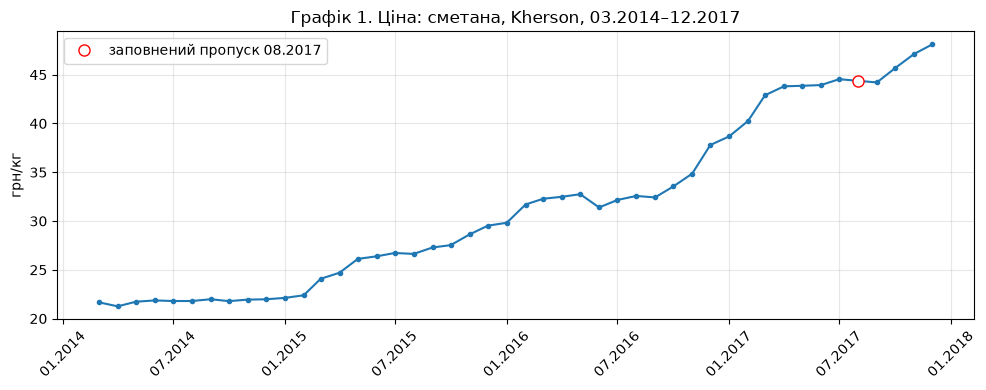

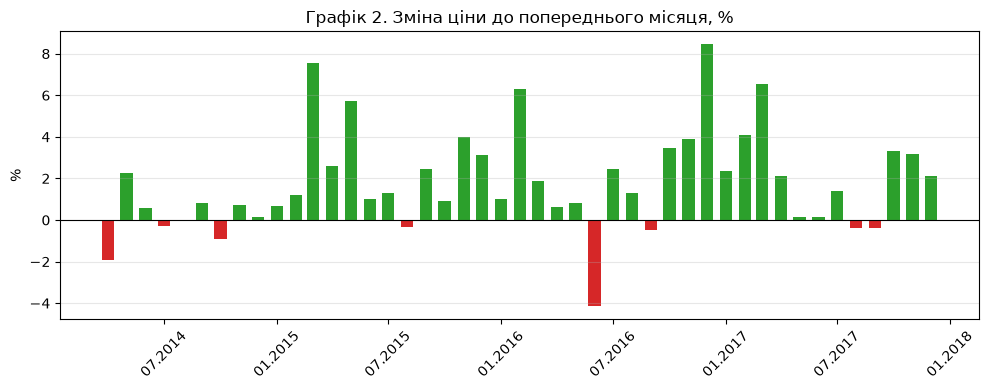

Найбільші зростання:
 date
2016-12-01    8.45
2015-03-01    7.56
2017-03-01    6.56
2016-02-01    6.28
2015-05-01    5.74
Падіння:
 date
2014-04-01   -1.91
2014-07-01   -0.27
2014-10-01   -0.89
2015-08-01   -0.35
2016-06-01   -4.15
2016-09-01   -0.46
2017-08-01   -0.37
2017-09-01   -0.38


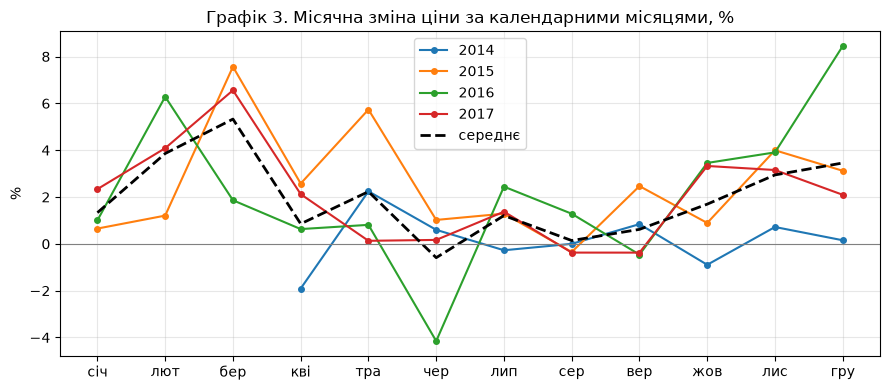

Середня місячна зміна за календарним місяцем, %:
 місяць
1     1.33
2     3.86
3     5.33
4     0.85
5     2.23
6    -0.59
7     1.21
8     0.14
9     0.62
10    1.69
11    2.94
12    3.45


In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ── Графік 1. Рівень ряду ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(y_filled.index, y_filled.values, '-o', ms=3, color='tab:blue')
ax.plot(gap, y_filled[gap], 'o', ms=8, mfc='white', mec='red',
        label='заповнений пропуск 08.2017')
ax.set_title(f'Графік 1. Ціна: {GOOD_UA}, {MARKET}, 03.2014–12.2017')
ax.set_ylabel('грн/кг'); ax.grid(alpha=.3); ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# ── Графік 2. Місячна зміна, % ──────────────────────────────────
pct = y_filled.pct_change() * 100
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['tab:red' if v < 0 else 'tab:green' for v in pct.fillna(0)]
ax.bar(pct.index, pct.values, width=20, color=colors)
ax.axhline(0, color='black', lw=.8)
ax.set_title('Графік 2. Зміна ціни до попереднього місяця, %')
ax.set_ylabel('%'); ax.grid(axis='y', alpha=.3)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

print('Найбільші зростання:\n', pct.nlargest(5).round(2).to_string())
print('Падіння:\n', pct[pct < 0].round(2).to_string())

# ── Графік 3. Сезонний графік: місячна зміна за календарним місяцем ──
seas = pd.DataFrame({'рік': pct.index.year, 'місяць': pct.index.month, 'pct': pct.values}).dropna()
fig, ax = plt.subplots(figsize=(9, 4))
for yr, g in seas.groupby('рік'):
    ax.plot(g['місяць'], g['pct'], '-o', ms=4, label=str(yr))
mean_by_month = seas.groupby('місяць')['pct'].mean()
ax.plot(mean_by_month.index, mean_by_month.values, 'k--', lw=2, label='середнє')
ax.axhline(0, color='grey', lw=.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['січ','лют','бер','кві','тра','чер','лип','сер','вер','жов','лис','гру'])
ax.set_title('Графік 3. Місячна зміна ціни за календарними місяцями, %')
ax.set_ylabel('%'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

print('Середня місячна зміна за календарним місяцем, %:\n', mean_by_month.round(2).to_string())

**Висновок до завдання 3:**

Графік 1 (лінійний, звичайна шкала). Питання: як змінювався рівень ціни за весь період. Ряд — це впорядковані в часі спостереження, де важлива неперервність і напрямок, тому обрано лінію. Шкала лінійна: ціна змінилася з 21.67 до 48.10 грн (≈2.2 раза), а за такого діапазону логарифмічна шкала нічого не додає, лише ускладнює читання абсолютних значень у гривнях. Заповнений пропуск позначено окремо, щоб не видавати його за вимір. Висновок: ряд має сильний висхідний тренд, а сам рівень ціни переважно росте сходинками, а не рівномірно.

Графік 2 (стовпчики, базова лінія 0). Питання: коли і наскільки швидко росла ціна. Місячна зміна — окрема величина для кожного місяця, яка може бути додатною чи від'ємною, тому обрано стовпчики від нуля з кольором за знаком. Відносна зміна у % дає змогу порівнювати 2014 і 2017 роки, хоча рівні цін там різні. Висновок: найбільші стрибки припадають на 12.2016 (+8.4 %), 03.2015 (+7.6 %), 03.2017 (+6.6 %) і 02.2016 (+6.3 %). Падінь лише 8 з 45, і всі невеликі; найбільше — у 06.2016 (−4.2 %).

Графік 3 (сезонний: лінія на кожен рік, вісь X — календарний місяць). Питання: чи повторюється всередині року однаковий малюнок. На графіку рівня сезонність ховається за трендом, тому взято місячні зміни у %, а роки накладено один на одного. Висновок: ціна найшвидше росте з листопада по березень (у середньому +2.9…+5.3 % на місяць) і майже стоїть з червня по вересень (−0.6…+1.2 %). Схоже на сезонний ефект (влітку молока більше, взимку менше).

Неочікувана знахідка: у 2014 році ціна майже не змінилася (21.25–21.98 грн), хоча гривня тоді вже сильно девальвувала. Зростання почалося лише в березні 2015 (+7.6 %), тобто роздрібна ціна сметани реагувала на кризу з запізненням приблизно в рік. Після цього за 2015–2017 роки вона подвоїлася.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

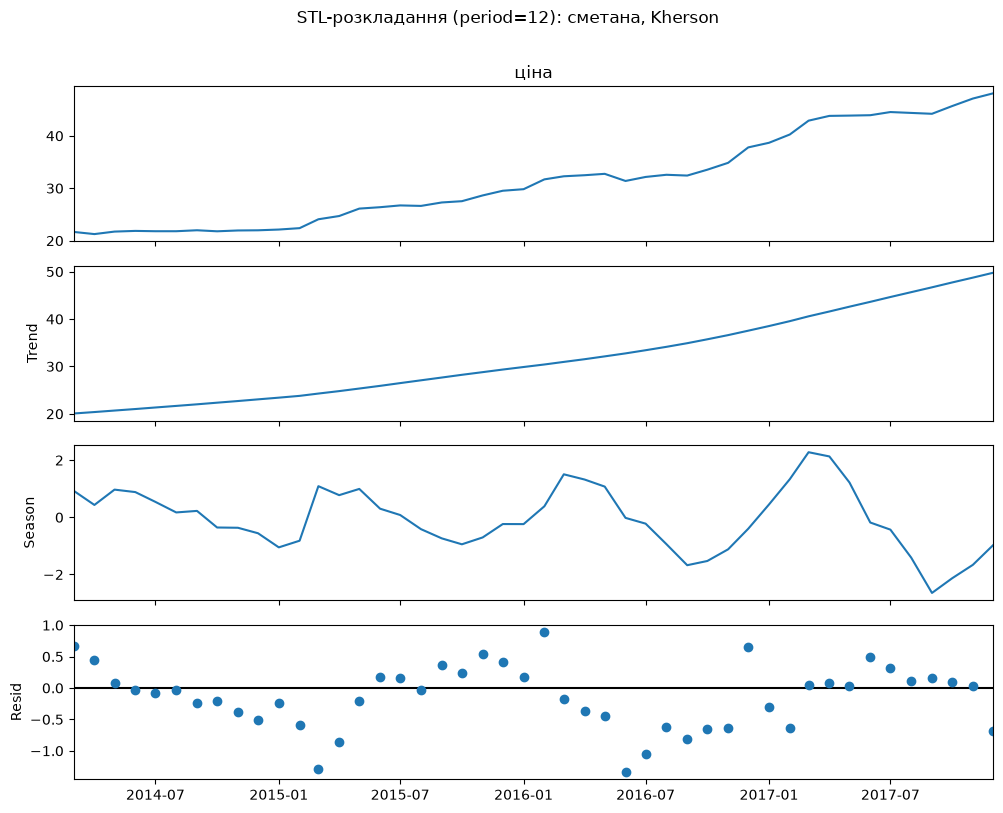

Сила тренду       F_T = 0.997
Сила сезонності   F_S = 0.823
Поріг: 0.64 → сезонність Є

Середня сезонна складова за місяцем, грн:
date
1    -0.28
2     0.30
3     1.45
4     1.17
5     1.06
6     0.25
7    -0.01
8    -0.65
9    -1.21
10   -1.24
11   -0.96
12   -0.54

Розмах сезонної складової: 4.92 грн при рівні ряду 21.3–48.1 грн


In [6]:
from statsmodels.tsa.seasonal import STL

stl = STL(y_filled, period=12).fit()

fig = stl.plot()
fig.set_size_inches(10, 8)
fig.suptitle(f'STL-розкладання (period=12): {GOOD_UA}, {MARKET}', y=1.01)
plt.tight_layout(); plt.show()

T, S, R = stl.trend, stl.seasonal, stl.resid

F_T = max(0, 1 - np.var(R) / np.var(T + R))
F_S = max(0, 1 - np.var(R) / np.var(S + R))
print(f'Сила тренду       F_T = {F_T:.3f}')
print(f'Сила сезонності   F_S = {F_S:.3f}')
print(f'Поріг: 0.64 → сезонність {"Є" if F_S > 0.64 else "НЕМАЄ"}')

print('\nСередня сезонна складова за місяцем, грн:')
print(S.groupby(S.index.month).mean().round(2).to_string())
print(f'\nРозмах сезонної складової: {S.max() - S.min():.2f} грн '
      f'при рівні ряду {y_filled.min():.1f}–{y_filled.max():.1f} грн')

Ряд розкладено методом STL з періодом 12 на тренд, сезонну складову й залишок.

Сила тренду F_T = 0.997, тобто майже вся мінливість ряду пояснюється трендом: ціна стабільно зростає з ≈22 до ≈48 грн.

Сила сезонності F_S = 0.823, що вище за порогове значення 0.64, тож сезонність у ряді є. Сезонна складова має чіткий малюнок: ціна вища за тренд у березні–травні (+1.1…+1.45 грн) і нижча у вересні–листопаді (−1.0…−1.2 грн). Це узгоджується з графіком 3 із завдання 3: взимку ціна росте швидко, а влітку майже стоїть, що можна пов'язати з більшою пропозицією молока влітку.

Водночас сезонність помірна. Її розмах — близько 2.7 грн, тобто 5–10 % від рівня ціни, набагато менше, ніж вплив тренду. До того ж ряд охоплює лише ≈3.8 річних цикли, тож кожне сезонне значення оцінене лише за 3–4 спостереженнями, і для впевненішого висновку потрібен довший ряд.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

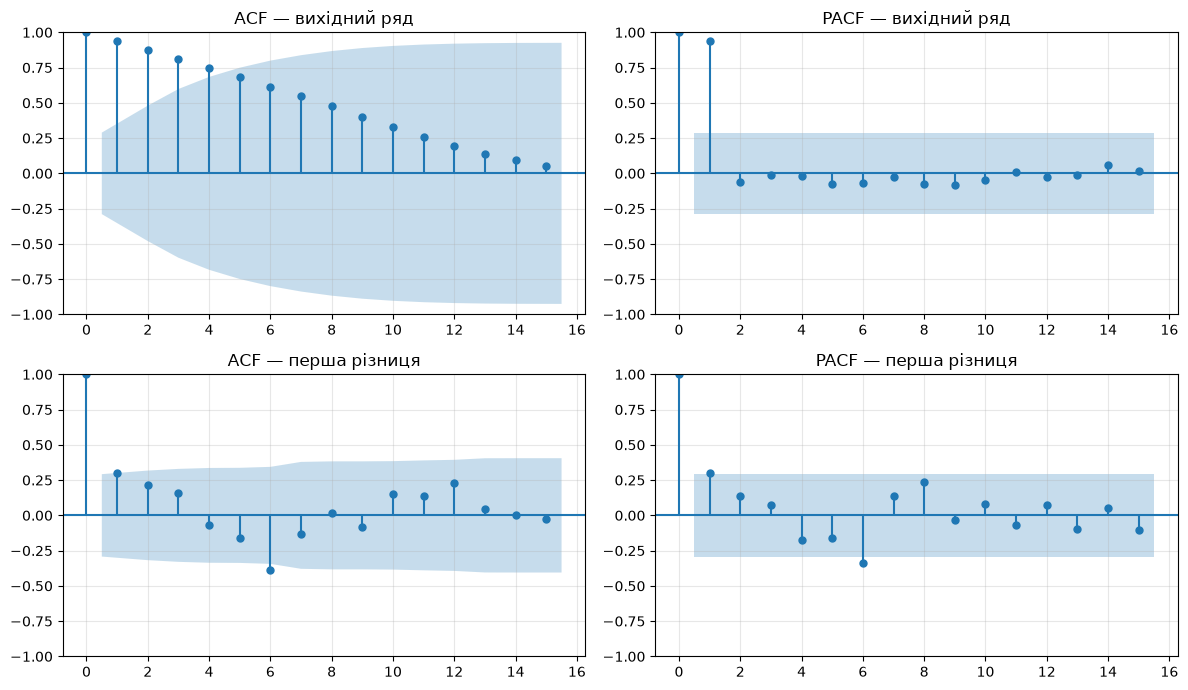

,ряд,p ADF,висновок ADF,p KPSS,висновок KPSS,тести узгоджуються
0,вихідний ряд,0.9991,нестаціонарний,0.01,нестаціонарний,так
1,перша різниця,0.0015,стаціонарний,0.10,стаціонарний,так


H0 ADF:  є одиничний корінь (ряд НЕстаціонарний) → p < 0.05 означає стаціонарність
H0 KPSS: ряд стаціонарний                       → p < 0.05 означає НЕстаціонарність
Примітка: KPSS обрізає p до діапазону [0.01; 0.10], тобто 0.01 означає «≤ 0.01», а 0.1 — «≥ 0.10»


In [7]:
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

y_diff = y_filled.diff().dropna()     # перша різниця (45 значень)
LAGS = 15

# ── ACF і PACF: до і після диференціювання ──
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(y_filled,  lags=LAGS, ax=axes[0, 0], title='ACF — вихідний ряд')
plot_pacf(y_filled, lags=LAGS, ax=axes[0, 1], title='PACF — вихідний ряд', method='ywm')
plot_acf(y_diff,    lags=LAGS, ax=axes[1, 0], title='ACF — перша різниця')
plot_pacf(y_diff,   lags=LAGS, ax=axes[1, 1], title='PACF — перша різниця', method='ywm')
for ax in axes.flat:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# ── Тести ADF і KPSS ──
def tests(x):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')          # KPSS попереджає, коли p за межами таблиці
        p_adf  = adfuller(x, autolag='AIC')[1]
        p_kpss = kpss(x, regression='c', nlags='auto')[1]
    return p_adf, p_kpss

rows = []
for name, x in [('вихідний ряд', y_filled), ('перша різниця', y_diff)]:
    p_adf, p_kpss = tests(x)
    adf_concl  = 'стаціонарний' if p_adf  < 0.05 else 'нестаціонарний'
    kpss_concl = 'стаціонарний' if p_kpss > 0.05 else 'нестаціонарний'
    rows.append([name, round(p_adf, 4), adf_concl, round(p_kpss, 4), kpss_concl,
                 'так' if adf_concl == kpss_concl else 'НІ'])

table = pd.DataFrame(rows, columns=['ряд', 'p ADF', 'висновок ADF',
                                    'p KPSS', 'висновок KPSS', 'тести узгоджуються'])
display(table)

print('H0 ADF:  є одиничний корінь (ряд НЕстаціонарний) → p < 0.05 означає стаціонарність')
print('H0 KPSS: ряд стаціонарний                       → p < 0.05 означає НЕстаціонарність')
print('Примітка: KPSS обрізає p до діапазону [0.01; 0.10], тобто 0.01 означає «≤ 0.01», а 0.1 — «≥ 0.10»')

**Висновок до завдання 5:**

ACF вихідного ряду спадає дуже повільно: 0.94 на лагу 1, 0.81 на лагу 3, і значущою лишається приблизно до 9-го лагу. Це типова ознака нестаціонарного ряду з трендом: кожне значення сильно залежить від попереднього, бо ряд постійно «дрейфує» вгору. PACF вихідного ряду має один величезний пік на лагу 1 (0.96), а далі обривається, тобто поведінка схожа на випадкове блукання.

Після першого диференціювання повільне спадання ACF зникає. Значущими (за межею ≈±0.29) лишаються лише окремі лаги: ACF на лагу 1 (0.30, на межі значущості) і на лагу 6 (−0.39); PACF на лагах 1 (0.31) і 6 (−0.40). На лагу 12 значущої автокореляції немає (0.23), що теж свідчить про слабкість сезонності.

Тести:

Вихідний ряд: ADF p = 0.999 > 0.05, тож гіпотезу про одиничний корінь не відхиляємо. KPSS p ≤ 0.01 < 0.05, тож гіпотезу про стаціонарність відхиляємо. Обидва тести кажуть, що ряд нестаціонарний.
Перша різниця: ADF p = 0.0015 < 0.05, тож одиничний корінь відхиляємо. KPSS p ≥ 0.10 > 0.05, тож стаціонарність не відхиляємо. Обидва тести кажуть, що ряд стаціонарний.

Тести узгоджуються між собою в обох випадках. Нульові гіпотези в них протилежні: в ADF H₀ — «ряд нестаціонарний», а в KPSS H₀ — «ряд стаціонарний». Тому малий p в ADF означає стаціонарність, а малий p у KPSS — навпаки, нестаціонарність. З урахуванням цього обидва тести дають однаковий результат: вихідний ряд нестаціонарний, а одного диференціювання достатньо, щоб зробити його стаціонарним. Отже, порядок інтегрованості d = 1.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

Фолд 1: навчання 03.2014–03.2016 (25 міс.), тест 04.2016–06.2016
Фолд 2: навчання 03.2014–06.2016 (28 міс.), тест 07.2016–09.2016
Фолд 3: навчання 03.2014–09.2016 (31 міс.), тест 10.2016–12.2016
Фолд 4: навчання 03.2014–12.2016 (34 міс.), тест 01.2017–03.2017
Фолд 5: навчання 03.2014–03.2017 (37 міс.), тест 04.2017–06.2017
Фолд 6: навчання 03.2014–06.2017 (40 міс.), тест 07.2017–09.2017
Фолд 7: навчання 03.2014–09.2017 (43 міс.), тест 10.2017–12.2017

Рухомий початок (7 × 3):


,MAE,RMSE,MAPE
наївний,1.639,2.207,4.095
сезонний наївний,9.054,9.445,22.502
середнє,11.920,12.570,29.389
дрейф,1.171,1.631,2.960


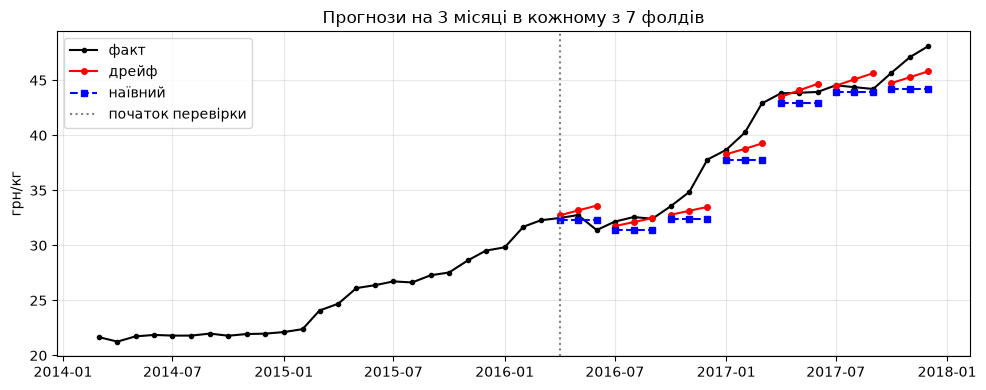

Навчальних точок: 34, тестових: 12
Випадковий поділ 75/25:


,MAE,RMSE,MAPE
наївний,1.040,1.380,3.354
сезонний наївний,8.970,9.196,32.402
середнє,8.979,9.392,32.520
дрейф,0.878,1.052,3.133


У скільки разів рухомий початок гірший за випадковий поділ:


,MAE,RMSE,MAPE
наївний,1.58,1.60,1.22
сезонний наївний,1.01,1.03,0.69
середнє,1.33,1.34,0.90
дрейф,1.33,1.55,0.94


In [8]:
# ── базисні прогнози: train → прогноз на h кроків ──
def f_naive(tr, h):  return np.repeat(tr[-1], h)
def f_snaive(tr, h): return np.array([tr[len(tr) - 12 + (i % 12)] for i in range(h)])
def f_mean(tr, h):   return np.repeat(tr.mean(), h)
def f_drift(tr, h):
    slope = (tr[-1] - tr[0]) / (len(tr) - 1)
    return tr[-1] + slope * np.arange(1, h + 1)

BASELINES = {'наївний': f_naive, 'сезонний наївний': f_snaive,
             'середнє': f_mean, 'дрейф': f_drift}

def metrics(actual, pred):
    e = actual - pred
    return {'MAE':  np.mean(np.abs(e)),
            'RMSE': np.sqrt(np.mean(e ** 2)),
            'MAPE': np.mean(np.abs(e / actual)) * 100}

v = y_filled.values
n, K, H = len(v), 7, 3

# ── межі фолдів ──
folds = []
for k in range(K):
    end = n - (K - k) * H                      # навчання: v[:end], тест: v[end:end+H]
    folds.append(end)
    print(f'Фолд {k+1}: навчання 03.2014–{y_filled.index[end-1]:%m.%Y} ({end} міс.), '
          f'тест {y_filled.index[end]:%m.%Y}–{y_filled.index[end+H-1]:%m.%Y}')

# ── рухомий початок ──
def rolling_origin(f):
    A, P = [], []
    for end in folds:
        A.extend(v[end:end + H])
        P.extend(f(v[:end], H))
    return np.array(A), np.array(P)

res_ro = pd.DataFrame({name: metrics(*rolling_origin(f))
                       for name, f in BASELINES.items()}).T
print('\nРухомий початок (7 × 3):')
display(res_ro.round(3))

# ── графік прогнозів найкращого базису ──
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(y_filled.index, v, 'k-o', ms=3, label='факт')
for i, end in enumerate(folds):
    idx = y_filled.index[end:end + H]
    ax.plot(idx, f_drift(v[:end], H), 'r-o', ms=4, label='дрейф' if i == 0 else None)
    ax.plot(idx, f_naive(v[:end], H), 'b--s', ms=4, label='наївний' if i == 0 else None)
ax.axvline(y_filled.index[folds[0]], color='grey', ls=':', label='початок перевірки')
ax.set_title('Прогнози на 3 місяці в кожному з 7 фолдів')
ax.set_ylabel('грн/кг'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

# ── для порівняння: випадковий поділ 75/25 ──
rng = np.random.default_rng(42)
perm = rng.permutation(n)
n_tr = round(0.75 * n)
tr_idx, te_idx = np.sort(perm[:n_tr]), np.sort(perm[n_tr:])
print(f'Навчальних точок: {len(tr_idx)}, тестових: {len(te_idx)}')

slope_all = (v[tr_idx[-1]] - v[tr_idx[0]]) / (tr_idx[-1] - tr_idx[0])
preds = {k: [] for k in BASELINES}
for t in te_idx:
    near = tr_idx[np.argmin(np.abs(tr_idx - t))]     # найближча навчальна точка (може бути з МАЙБУТНЬОГО)
    same = tr_idx[(tr_idx - t) % 12 == 0]            # той самий календарний місяць
    preds['наївний'].append(v[near])
    preds['сезонний наївний'].append(v[same[np.argmin(np.abs(same - t))]] if len(same) else v[near])
    preds['середнє'].append(v[tr_idx].mean())         # середнє включає майбутні ціни
    preds['дрейф'].append(v[near] + slope_all * (t - near))

res_rand = pd.DataFrame({k: metrics(v[te_idx], np.array(p)) for k, p in preds.items()}).T
print('Випадковий поділ 75/25:')
display(res_rand.round(3))
print('У скільки разів рухомий початок гірший за випадковий поділ:')
display((res_ro / res_rand).round(2))

**Висновок до завдання 6:**

Чотири базисні прогнози оцінено перевіркою з рухомим початком: 7 фолдів по 3 кроки, навчальна частина розширюється від 25 до 43 місяців, перевіряються останні 21 місяць (04.2016–12.2017).

Найкращий базис — дрейф: MAE = 1.171 грн, RMSE = 1.631, MAPE = 2.96 %. Другий — наївний (MAE = 1.639, MAPE = 4.10 %). Сезонний наївний (MAPE 22.5 %) і середнє (MAPE 29.4 %) — у рази гірші.

Пояснення через властивості ряду: у ряді дуже сильний тренд (F_T = 0.997), ціна майже весь час росте. Дрейф — єдиний базис, що закладає зростання в прогноз, тому й виграє. Наївний прогноз застигає на останньому значенні й систематично відстає від тренду, але для 3 місяців це відставання невелике. Сезонний наївний бере ціну рік тому, а за рік сметана дорожчала на 20–30 %, тож він стабільно занижує прогноз. Помірна сезонність (F_S = 0.82) цього не компенсує. Середнє найгірше: воно включає ціни 2014 року (≈22 грн) і для ряду з трендом не має сенсу.

Випадковий поділ 75/25 дає для дрейфу MAE = 0.878 і RMSE = 1.052, тобто в 1.33 раза (за MAE) і в 1.55 раза (за RMSE) оптимістичніше, ніж рухомий початок. Для наївного різниця — у 1.58 раза. Причина — витік інформації з майбутнього: за випадкового поділу тестові місяці розкидані по всьому ряду, і в навчальну частину потрапляють місяці, які йдуть після них. Модель фактично «бачить відповідь» і заповнює пропуски між відомими сусідами, а не прогнозує вперед. У реальності майбутніх цін ніхто не знає, тому випадковий поділ для часових рядів дає завищену оцінку якості, і використовувати його не можна.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

,MAE,RMSE,MAPE
дрейф,1.171,1.631,2.960
"ARIMA(1,1,0) + дрейф",1.272,1.646,3.222
наївний,1.639,2.207,4.095
"ARIMA(1,1,1)",1.710,2.174,4.402
сезонний наївний,9.054,9.445,22.502
середнє,11.920,12.570,29.389


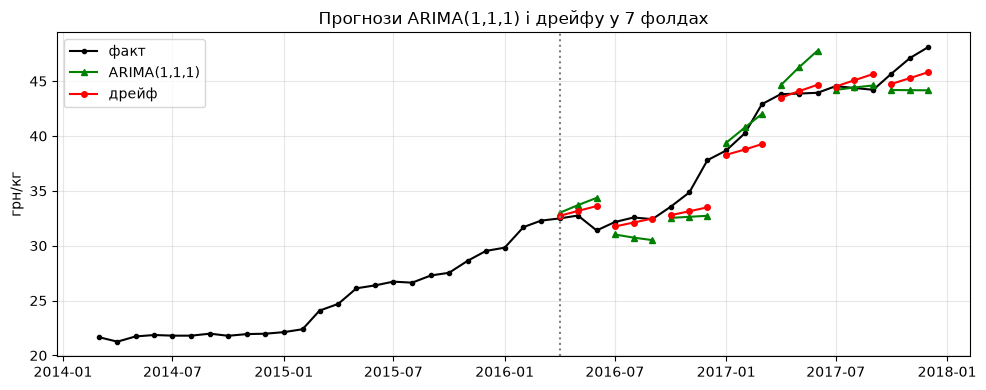

ar.L1     0.859
ma.L1    -0.471
sigma2    0.610
dtype: float64


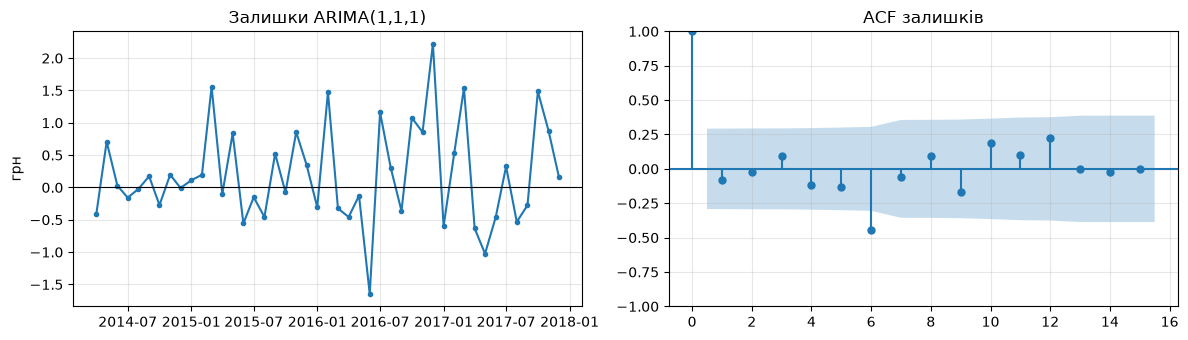

Тест Льюнга–Бокса (H0: залишки — білий шум):


,lb_stat,lb_pvalue
6,12.982481,0.043315
12,21.179174,0.047817


In [9]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

def arima_forecast(order, trend=None):
    def f(tr, h):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            return ARIMA(tr, order=order, trend=trend).fit().forecast(h)
    return f

# ── 1. ARIMA(1,1,1) на тих самих 7 фолдах × 3 кроки ──
A, P_arima = rolling_origin(arima_forecast((1, 1, 1)))
m_arima = metrics(A, P_arima)

# ── 2. порядок за ACF/PACF: ARIMA(1,1,0) з дрейфом ──
_, P_own = rolling_origin(arima_forecast((1, 1, 0), trend='t'))
m_own = metrics(A, P_own)

# ── 3. порівняння з базисами ──
comp = pd.concat([res_ro,
                  pd.DataFrame({'ARIMA(1,1,1)': m_arima,
                                'ARIMA(1,1,0) + дрейф': m_own}).T])
display(comp.round(3).sort_values('MAE'))

# ── графік прогнозів ARIMA(1,1,1) vs дрейф ──
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(y_filled.index, v, 'k-o', ms=3, label='факт')
for i, end in enumerate(folds):
    idx = y_filled.index[end:end + H]
    ax.plot(idx, P_arima[i*H:(i+1)*H], 'g-^', ms=4, label='ARIMA(1,1,1)' if i == 0 else None)
    ax.plot(idx, f_drift(v[:end], H), 'r-o', ms=4, label='дрейф' if i == 0 else None)
ax.axvline(y_filled.index[folds[0]], color='grey', ls=':')
ax.set_title('Прогнози ARIMA(1,1,1) і дрейфу у 7 фолдах')
ax.set_ylabel('грн/кг'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

# ── 4. залишки ARIMA(1,1,1) на всьому ряді ──
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    fit = ARIMA(y_filled, order=(1, 1, 1)).fit()
print(fit.params.round(3))
resid = fit.resid[1:]          # перший залишок — артефакт диференціювання

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(resid.index, resid.values, 'o-', ms=3)
axes[0].axhline(0, color='black', lw=.8)
axes[0].set_title('Залишки ARIMA(1,1,1)'); axes[0].set_ylabel('грн'); axes[0].grid(alpha=.3)
plot_acf(resid, lags=15, ax=axes[1], title='ACF залишків')
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print('Тест Льюнга–Бокса (H0: залишки — білий шум):')
display(acorr_ljungbox(resid, lags=[6, 12]))

**Висновок до завдання 7:**

1. ARIMA(1,1,1) на рухомому початку (7 × 3) дала MAE = 1.710 грн, RMSE = 2.174, MAPE = 4.40 %.

2. Порядок за ACF і PACF. d = 1, бо за завданням 5 одна різниця робить ряд стаціонарним. На PACF першої різниці значущий лаг 1 (0.31), після нього PACF обривається, тому p = 1. ACF першої різниці на лагу 1 лише на межі значущості (0.30), чіткого обриву немає, тож q = 0. Значущий лаг 6 на обох графіках я не включаю: модель AR(6) на 45 точках мала б забагато параметрів і перенавчилася б (перевірка дала MAE 1.88, гірше). Крім того, ряд має сильний тренд, а ARIMA з d = 1 без константи прогнозує без зростання, тому я додаю дрейф (константу в різницях, trend='t'). Обраний порядок — ARIMA(1,1,0) з дрейфом: MAE = 1.272, RMSE = 1.646, MAPE = 3.22 %.

3. Порівняння з найкращим базисом. ARIMA(1,1,1) програла дрейфу за всіма метриками (MAE 1.710 проти 1.171, тобто на 46 % гірше) і навіть простому наївному прогнозу за MAE (1.710 проти 1.639). ARIMA(1,1,0) з дрейфом значно краща за (1,1,1), але теж трохи поступається чистому дрейфу. Отже, на цьому ряді ARIMA(1,1,1) гірша за найпростіше правило «продовжуй лінію». Причина в тому, що ARIMA(1,1,1) без константи не закладає зростання в прогноз, а саме зростання — головна властивість ряду. До того ж 25–43 точок замало, щоб надійно оцінити додаткові параметри AR і MA, тож вони додають шум, а не точність. Модель ARIMA(0,1,0) з дрейфом дає рівно ті самі прогнози, що й базис «дрейф». Тобто найкраща модель для цього ряду — це просто випадкове блукання з дрейфом.

4. Залишки. Графік залишків коливається навколо нуля без тренду, але в ACF залишків значущий лаг 6 (≈ −0.44), а тест Льюнга–Бокса відхиляє гіпотезу про білий шум (p = 0.043 для 6 лагів, p = 0.048 для 12). Отже, у залишках лишилася структура: піврічний ритм «зима — швидке зростання, літо — затишшя», який ARIMA(1,1,1) не вловлює. 

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Точка зміни режиму: 03.2017
t-статистика:        16.07
Середнє до:          27.85 грн (36 міс.)
Середнє після:       44.85 грн (10 міс.)
Мінімальне |t| серед усіх кандидатів: 8.61


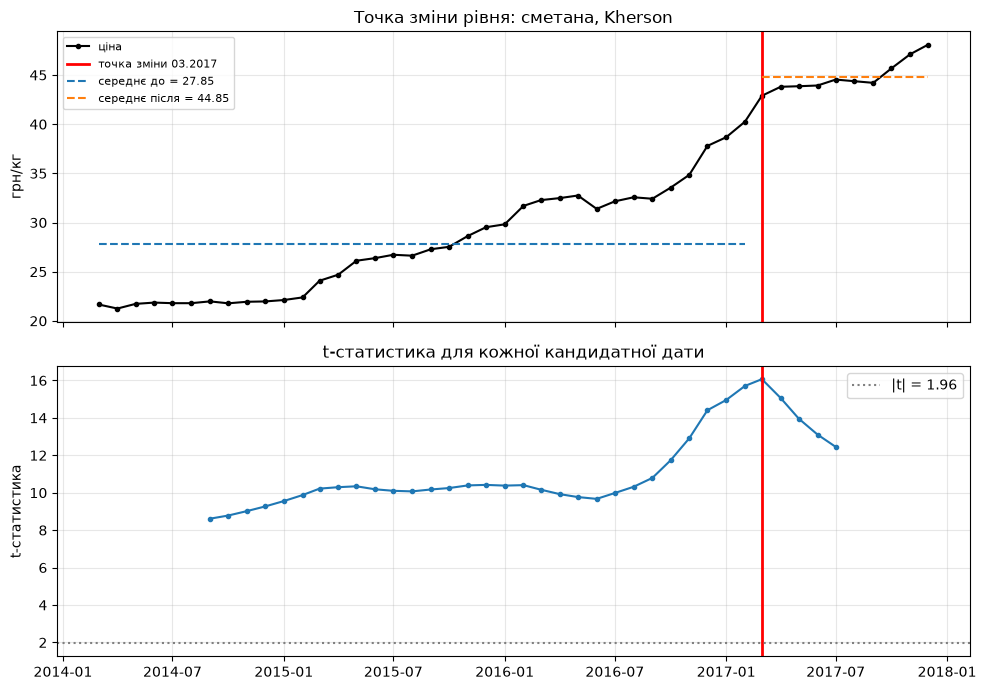


max|t| у рядах без зламу: медіана 13.3, 95-й перцентиль 15.7
p-значення (Монте-Карло): 0.036


In [10]:
from scipy import stats

MIN_SEG = 6

def scan(x):
    """повертає t-статистику Велча для кожної кандидатної точки"""
    return np.array([stats.ttest_ind(x[t:], x[:t], equal_var=False)[0]
                     for t in range(MIN_SEG, len(x) - MIN_SEG + 1)])

t_stats = scan(v)
cand_dates = y_filled.index[MIN_SEG:n - MIN_SEG + 1]
best = int(np.argmax(np.abs(t_stats)))
tau = best + MIN_SEG
cp_date = y_filled.index[tau]
mean_before, mean_after = v[:tau].mean(), v[tau:].mean()

print(f'Точка зміни режиму: {cp_date:%m.%Y}')
print(f't-статистика:        {t_stats[best]:.2f}')
print(f'Середнє до:          {mean_before:.2f} грн ({tau} міс.)')
print(f'Середнє після:       {mean_after:.2f} грн ({n - tau} міс.)')
print(f'Мінімальне |t| серед усіх кандидатів: {np.abs(t_stats).min():.2f}')

# ── графік: ряд з точкою + t-статистика по датах ──
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax = axes[0]
ax.plot(y_filled.index, v, 'k-o', ms=3, label='ціна')
ax.axvline(cp_date, color='red', lw=2, label=f'точка зміни {cp_date:%m.%Y}')
ax.hlines(mean_before, y_filled.index[0], y_filled.index[tau - 1], colors='tab:blue', ls='--',
          label=f'середнє до = {mean_before:.2f}')
ax.hlines(mean_after, cp_date, y_filled.index[-1], colors='tab:orange', ls='--',
          label=f'середнє після = {mean_after:.2f}')
ax.set_ylabel('грн/кг'); ax.set_title(f'Точка зміни рівня: {GOOD_UA}, {MARKET}')
ax.grid(alpha=.3); ax.legend(fontsize=8)

axes[1].plot(cand_dates, t_stats, 'o-', ms=3)
axes[1].axvline(cp_date, color='red', lw=2)
axes[1].axhline(1.96, color='grey', ls=':', label='|t| = 1.96')
axes[1].set_ylabel('t-статистика'); axes[1].set_title('t-статистика для кожної кандидатної дати')
axes[1].grid(alpha=.3); axes[1].legend()
plt.tight_layout(); plt.show()

# ── значущість: порівняння з рядами БЕЗ точки зміни ──
# моделюємо 2000 випадкових блукань з тим самим дрейфом і розкидом, що в нашому ряді,
# і дивимось, яке max|t| сканування знаходить у них просто випадково
d = np.diff(v)
rng = np.random.default_rng(0)
sim_max = np.array([
    np.abs(scan(v[0] + np.r_[0, np.cumsum(rng.normal(d.mean(), d.std(ddof=1), n - 1))])).max()
    for _ in range(2000)
])
p_mc = np.mean(sim_max >= abs(t_stats[best]))
print(f'\nmax|t| у рядах без зламу: медіана {np.median(sim_max):.1f}, 95-й перцентиль {np.percentile(sim_max, 95):.1f}')
print(f'p-значення (Монте-Карло): {p_mc:.3f}')

**Висновок до завдання 8:**

Сканування за t-статистикою знайшло точку зміни рівня в березні 2017 року: t = 16.07, середній рівень до — 27.85 грн (36 місяців), після — 44.85 грн (10 місяців).

Чи значуща ця точка. Звичайне p-значення t-тесту тут ≈ 0, але йому не можна довіряти з трьох причин:

У ряді з сильним трендом будь-яка дата дає величезне t: мінімальне |t| серед усіх кандидатів — 8.6. Будь-яке розбиття ряду, що росте, дасть «до» нижче за «після».
t-тест припускає незалежні спостереження, а ціни сусідніх місяців сильно корельовані (ACF лагу 1 = 0.94).
Ми перебрали 35 дат і взяли найкращу, тобто це множинне порівняння.

Тому значущість була перевірена інакше: змоделювано 2000 рядів без жодного зламу (випадкові блукання з тим самим дрейфом і розкидом) і провдено спостереження: яке max|t| сканування знаходить у них випадково. Медіана вийшла 13.3, 95-й перцентиль — 15.7. Наше t = 16.07 лише трохи вище за цю межу, p ≈ 0.04. Отже, точка на межі значущості: формально p < 0.05, але запас мінімальний, і впевнено стверджувати, що це окремий режим, а не звичайне зростання з дрейфом, не можна.

Зовнішнє пояснення. Точці передує найрізкіше зростання за весь період: з 12.2016 по 03.2017 ціна піднялася з 34.85 до 42.90 грн (+23 % за 4 місяці), після чого вийшла на плато ≈44 грн. Це збігається з подвоєнням мінімальної заробітної плати з 1 січня 2017 року, яке підштовхнуло ціни на продукти.

Відмінність від сезонного сплеску. Сезонна складова (завдання 4) теж має пік саме в березні, тому цю точку легко сплутати з сезоном. Але:

амплітуда сезонності — ≈ ±1.4 грн, а стрибок 12.2016–03.2017 — понад 8 грн, тобто вп'ятеро більше;
після сезонного піку ціна повертається до тренду, а тут вона лишилася на новому рівні до кінця ряду;
сезонний сплеск повторюється щороку, а стрибок такого масштабу був лише раз.

Отже, це зсув рівня, а не сезонний пік.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
from statsmodels.tsa.stattools import kpss

def get_series(market, good, fill=True):
    x = df[(df['ринок'] == market) & (df['товар'] == good)].copy()
    x['date'] = pd.to_datetime(dict(year=x['рік'], month=x['місяць'], day=1))
    x = x.set_index('date')['ціна'].sort_index()
    return x.reindex(grid).interpolate() if fill else x

raw  = get_series('Vinnytsia', 'Buckwheat grits - Retail', fill=False)
buck = get_series('Vinnytsia', 'Buckwheat grits - Retail')
beef = get_series('Vinnytsia', 'Meat (beef) - Retail')
lviv = get_series('Lviv', 'Buckwheat grits - Retail')

# Помилка 1: пропуск 08.2017 не виявлено
print('1) Спостережень:', len(raw), 'з 46; isna() без сітки:', raw.isna().sum(),
      '; після reindex:', raw.reindex(grid).isna().sum())

# Помилка 2: порівняння лише кінцевих точок
print(f'2) 03.2014: {buck.iloc[0]:.2f}, максимум {buck.max():.2f} ({buck.idxmax():%m.%Y}), '
      f'12.2017: {buck.iloc[-1]:.2f}')

# Помилка 3: MAE у гривнях для товарів з різною ціною
for name, x in [('гречка', buck), ('яловичина', beef)]:
    print(f'3) {name:10s} середня ціна {x.mean():6.2f} грн, '
          f'MAE наївного {x.diff().abs().mean():.2f} грн, '
          f'MAPE наївного {(x.diff().abs() / x).mean() * 100:.1f} %')

# Помилка 4: кореляція рівнів двох рядів з трендом
print(f'4) r рівнів = {buck.corr(lviv):.3f}, r місячних змін = {buck.diff().corr(lviv.diff()):.3f}')

# Помилка 5: STL «завжди знаходить» сезонність
r5 = STL(buck, period=12).fit()
print(f'5) F_S = {max(0, 1 - np.var(r5.resid) / np.var(r5.seasonal + r5.resid)):.3f} (поріг 0.64)')

# Помилка 6: перевернутий висновок ADF + подвійне диференціювання
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    print(f'6) рівень: ADF p = {adfuller(buck)[1]:.3f}, KPSS p = {kpss(buck, nlags="auto")[1]:.3f}; '
          f'1-ша різниця: ADF p = {adfuller(buck.diff().dropna())[1]:.3f}, '
          f'KPSS p = {kpss(buck.diff().dropna(), nlags="auto")[1]:.3f}')

# Помилка 7: «аномалії» за z-оцінкою на ряді з трендом
z = (buck - buck.mean()) / buck.std()
print(f'7) |z| > 1.3: {(z.abs() > 1.3).sum()} міс.; |z| > 2 (як заявлено в тексті): {(z.abs() > 2).sum()} міс.')

# Помилка 8: правильна оцінка ARIMA(1,1,1) рухомим початком
vb = buck.values
A, P_n, P_a = [], [], []
for end in folds:
    A.extend(vb[end:end + H])
    P_n.extend(np.repeat(vb[end - 1], H))
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        P_a.extend(ARIMA(vb[:end], order=(1, 1, 1)).fit().forecast(H))
A = np.array(A)
print(f'8) рухомий початок 7×3: MAE наївного = {np.mean(np.abs(A - P_n)):.2f}, '
      f'MAE ARIMA(1,1,1) = {np.mean(np.abs(A - np.array(P_a))):.2f} грн '
      f'(середня ціна {buck.mean():.1f} грн)')

1) Спостережень: 45 з 46; isna() без сітки: 0 ; після reindex: 1
2) 03.2014: 7.16, максимум 36.93 (07.2016), 12.2017: 17.67
3) гречка     середня ціна  21.36 грн, MAE наївного 1.35 грн, MAPE наївного 6.1 %
3) яловичина  середня ціна  78.99 грн, MAE наївного 1.47 грн, MAPE наївного 1.9 %
4) r рівнів = 0.996, r місячних змін = 0.937
5) F_S = 0.611 (поріг 0.64)
6) рівень: ADF p = 0.348, KPSS p = 0.018; 1-ша різниця: ADF p = 0.040, KPSS p = 0.065
7) |z| > 1.3: 12 міс.; |z| > 2 (як заявлено в тексті): 0 міс.
8) рухомий початок 7×3: MAE наївного = 2.55, MAE ARIMA(1,1,1) = 2.77 грн (середня ціна 21.4 грн)


**Висновок до завдання 9:**

**Перелік знайдених помилок**

Нумерація клітинок — від початку зошита, разом із текстовими.

| № | Клітинка | Суть помилки | Чим небезпечна |
|---|---|---|---|
| 1 | 4 (розд. 1) | Пропуски перевірено через `isna()` без побудови повної місячної сітки. У ряді 45 спостережень замість 46: серпень 2017 просто відсутній як рядок, тому `isna()` показує 0. | Усі операції, що працюють за позицією (`shift(1)`, `shift(12)`, `diff()`), після 08.2017 зсуваються на місяць: наївна похибка за 09.2017 рахується між липнем і вереснем, а сезонний лаг порівнює різні місяці. |
| 2 | 6 (розд. 2) | Подорожчання оцінено лише за двома точками (03.2014 і 12.2017). Висновок про купівельну спроможність зроблено без даних про доходи. | Приховано головне: ціна зросла до 36.93 грн у 07.2016 (у 5.2 раза), а потім упала вдвічі. «Зросла у 2.5 раза» — випадковий результат вибору кінцевої дати. Номінальна ціна без доходів та інфляції нічого не каже про купівельну спроможність. |
| 3 | 8 (розд. 3) | Точність прогнозу двох товарів порівняно за MAE у гривнях, хоча яловичина в 3.7 раза дорожча за гречку (78 проти 21 грн). Метод не відповідає меті розділу. | MAE залежить від масштабу. У відносних похибках висновок протилежний: наївна похибка для гречки ≈ 7 %, для яловичини ≈ 2 %, тобто гречка прогнозується значно гірше. |
| 4 | 10 (розд. 4) | Кореляцію r = 0.996 пораховано між рівнями двох рядів із трендом, і з неї виведено, що Львів «визначає» ціни у Вінниці. | Кореляція рівнів рядів, що ростуть, завищена самим трендом (хибна кореляція). Кореляція не означає причинності: обидва ринки реагують на спільні чинники (урожай, курс, інфляція), а напрямку впливу кореляція не показує. |
| 5 | 12 (розд. 5) | Сезонність «доведено» тим, що STL виділив сезонну складову. Сила сезонності не обчислена. | STL повертає сезонну складову для будь-якого ряду, навіть для шуму. F_S = 0.61 — нижче за поріг 0.64, тож сезонність не підтверджено. Хибний висновок веде до використання сезонних моделей без підстав. |
| 6 | 14 (розд. 6) | Перевернуто висновок ADF: p = 0.233 > 0.05 означає, що H₀ (одиничний корінь, ряд нестаціонарний) не відхилено, а у звіті написано «стаціонарний». Потім ряд «для надійності» диференційовано двічі. KPSS не застосовано. | Висновок про стаціонарність прямо протилежний правильному. Подвійне диференціювання надмірне: одна різниця вже робить ряд стаціонарним, а зайва додає штучну від'ємну автокореляцію й погіршує прогноз. |
| 7 | 16 (розд. 7) | У тексті заявлено поріг 2σ, а в коді стоїть 1.3. z-оцінку рахують від загального середнього ряду з трендом. | За порогу 2σ аномалій нуль, тобто поріг підібрано під бажаний результат. «Аномаліями» стали весь 2014 рік (низький рівень) і пік 2016 року — звичайні ділянки тренду, а не нетипові події. |
| 8 | 18 (розд. 8) | Для часового ряду використано випадковий поділ 75/25 (`train_test_split`). Модель навчено на перемішаних точках, прогноз зроблено за межі ряду й порівняно з відсортованими (`np.sort`) тестовими значеннями з різних років. | Витік інформації з майбутнього. Пари «прогноз — факт» не відповідають одним і тим самим місяцям, тож MAE = 8.73 не має сенсу. |
| 9 | 18 (розд. 8) | MAE = 8.73 грн названо «високою точністю». Порівняння із сезонним наївним зроблено на іншому наборі точок (на всьому ряді), а з простим наївним прогнозом модель не порівняно взагалі. | 8.73 грн — це ≈ 40 % від середньої ціни, тобто модель дуже неточна. Правильна оцінка (рухомий початок, 7×3) показує, що ARIMA(1,1,1) (MAE ≈ 2.77) гірша за простий наївний прогноз (MAE ≈ 2.55). |
| 10 | 20 (розд. 9) | Прогноз зроблено моделлю ARIMA(2,2,1), яка ніде не перевірялась (оцінювали (1,1,1)), з надмірним d = 2, на 12 місяців уперед, без довірчих інтервалів. Висновок «ціна зростатиме» суперечить власному числу: прогноз на 12.2018 — 8.95 грн, удвічі нижче за 17.67 грн у 12.2017. | Висновок суперечить результату, а оцінка якості стосується іншої моделі. d = 2 механічно продовжує падіння 2017 року й веде прогноз до нереалістичних значень. Без інтервалів не видно невизначеності прогнозу. |
| 11 | 22 (розд. 10) | Стовпчикова діаграма з обрізаною віссю Y (від 0.995·min), у заголовку «2016 рік», хоча показано лише перше півріччя. | Довжина стовпчика має бути пропорційна значенню, тому вісь для стовпчиків мусить починатися з нуля. Обрізана вісь візуально перебільшує зростання в кілька разів, а вибір вікна приховує, що з другого півріччя 2016 ціна почала падати. |

Загальні висновки (клітинка 23) повторюють хибні твердження з розділів 4, 5, 6, 8 і 9, тому їх слід переписати повністю.

**Як виправити три найсерйозніші помилки**

1. **Перевернутий висновок ADF (клітинка 14).** Правильно: p = 0.233 > 0.05, H₀ не відхиляється, отже ряд **нестаціонарний**. Висновок слід підтвердити тестом KPSS із протилежною H₀ (p ≈ 0.02 < 0.05 — теж «нестаціонарний»). Потім узяти **одну** різницю й перевірити знову: ADF p ≈ 0.04, KPSS p ≈ 0.06 — ряд стаціонарний, d = 1. Друга різниця не потрібна.

2. **Випадковий поділ для оцінки моделі (клітинка 18).** Замість `train_test_split` слід використати ретроспективну перевірку з рухомим початком (наприклад, 7 фолдів × 3 кроки): модель навчається лише на минулому й прогнозує кілька наступних місяців, навчальна частина поступово розширюється. Обов'язкове порівняння з базисами (наївний, дрейф) на тих самих фолдах і відносна метрика (MAPE). Така перевірка показує, що ARIMA(1,1,1) не перевершує наївний прогноз.

3. **Невиявлений пропуск (клітинка 4).** Перед аналізом ряд слід привести до повної місячної сітки (`reindex(pd.date_range('2014-03-01', '2017-12-01', freq='MS'))`), виявити пропуск 08.2017 і заповнити його лінійною інтерполяцією. Без цього `shift`, `diff`, сезонний лаг і всі моделі після серпня 2017 працюють зі зсунутими даними.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
export = pd.DataFrame({
    'date':  y_filled.index.strftime('%Y-%m-%d'),   # текст РРРР-ММ-ДД, перше число місяця
    'price': y_filled.values.round(4),
})
export.to_csv('ряд_для_orange.csv', index=False, sep=',', encoding='utf-8')

# ── перевірка: читаємо файл назад ──
check = pd.read_csv('ряд_для_orange.csv', encoding='utf-8')
print('Стовпці:           ', check.columns.tolist())
print('Рядків даних:      ', len(check))
print('Порожніх значень:  ', check.isna().sum().sum())
print('Перша / остання дата:', check['date'].iloc[0], '/', check['date'].iloc[-1])
print('Значення за 2017-08-01:', check.loc[check['date'] == '2017-08-01', 'price'].item())
print('Збігається з Python-рядом:', np.allclose(check['price'], y_filled.values, atol=1e-4))

assert len(check) == 46 and check.isna().sum().sum() == 0
assert list(check.columns) == ['date', 'price']

with open('ряд_для_orange.csv', encoding='utf-8') as f:
    print('\nПерші рядки файлу:')
    for _ in range(4):
        print(f.readline().rstrip())

Стовпці:            ['date', 'price']
Рядків даних:       46
Порожніх значень:   0
Перша / остання дата: 2014-03-01 / 2017-12-01
Значення за 2017-08-01: 44.3734
Збігається з Python-рядом: True

Перші рядки файлу:
date,price
2014-03-01,21.6667
2014-04-01,21.2533
2014-05-01,21.73


**Висновок до завдання 10:**

**Висновок до завдання 10:**

Підготовлений ряд (з пропуском 08.2017, заповненим лінійною інтерполяцією, значення 44.3734 грн) збережено у файл `ряд_для_orange.csv` у заданому форматі: два стовпці — `date` (текст у форматі РРРР-ММ-ДД, перше число місяця) і `price` (число), роздільник — кома, кодування UTF-8.

Перевірка повторним зчитуванням файлу підтвердила, що він містить рівно 46 рядків даних (03.2014–12.2017) плюс заголовок і не має жодного порожнього значення. Значення у файлі збігаються з рядом, який використовувався в Частині 1, з точністю до 10⁻⁴. Отже, Orange отримає точно ті самі дані, що й Python, і будь-які розбіжності в Частині 2 не можна буде пояснити різницею вхідних даних.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

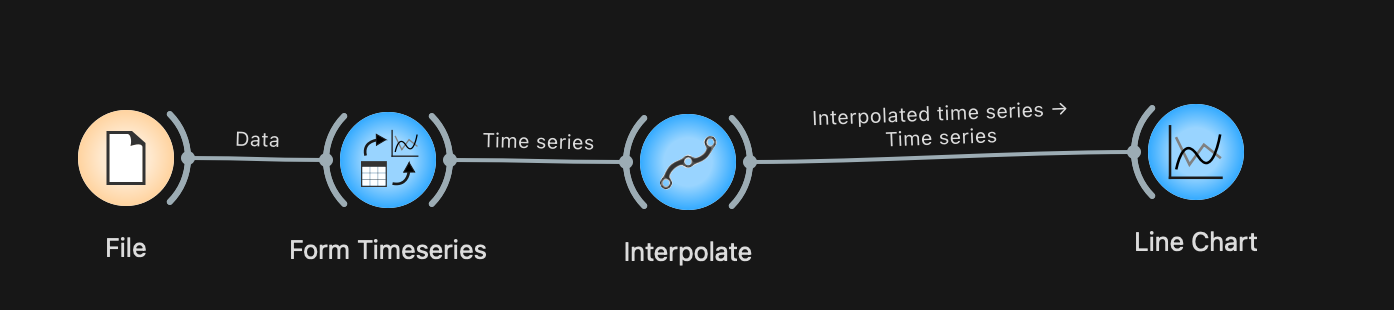

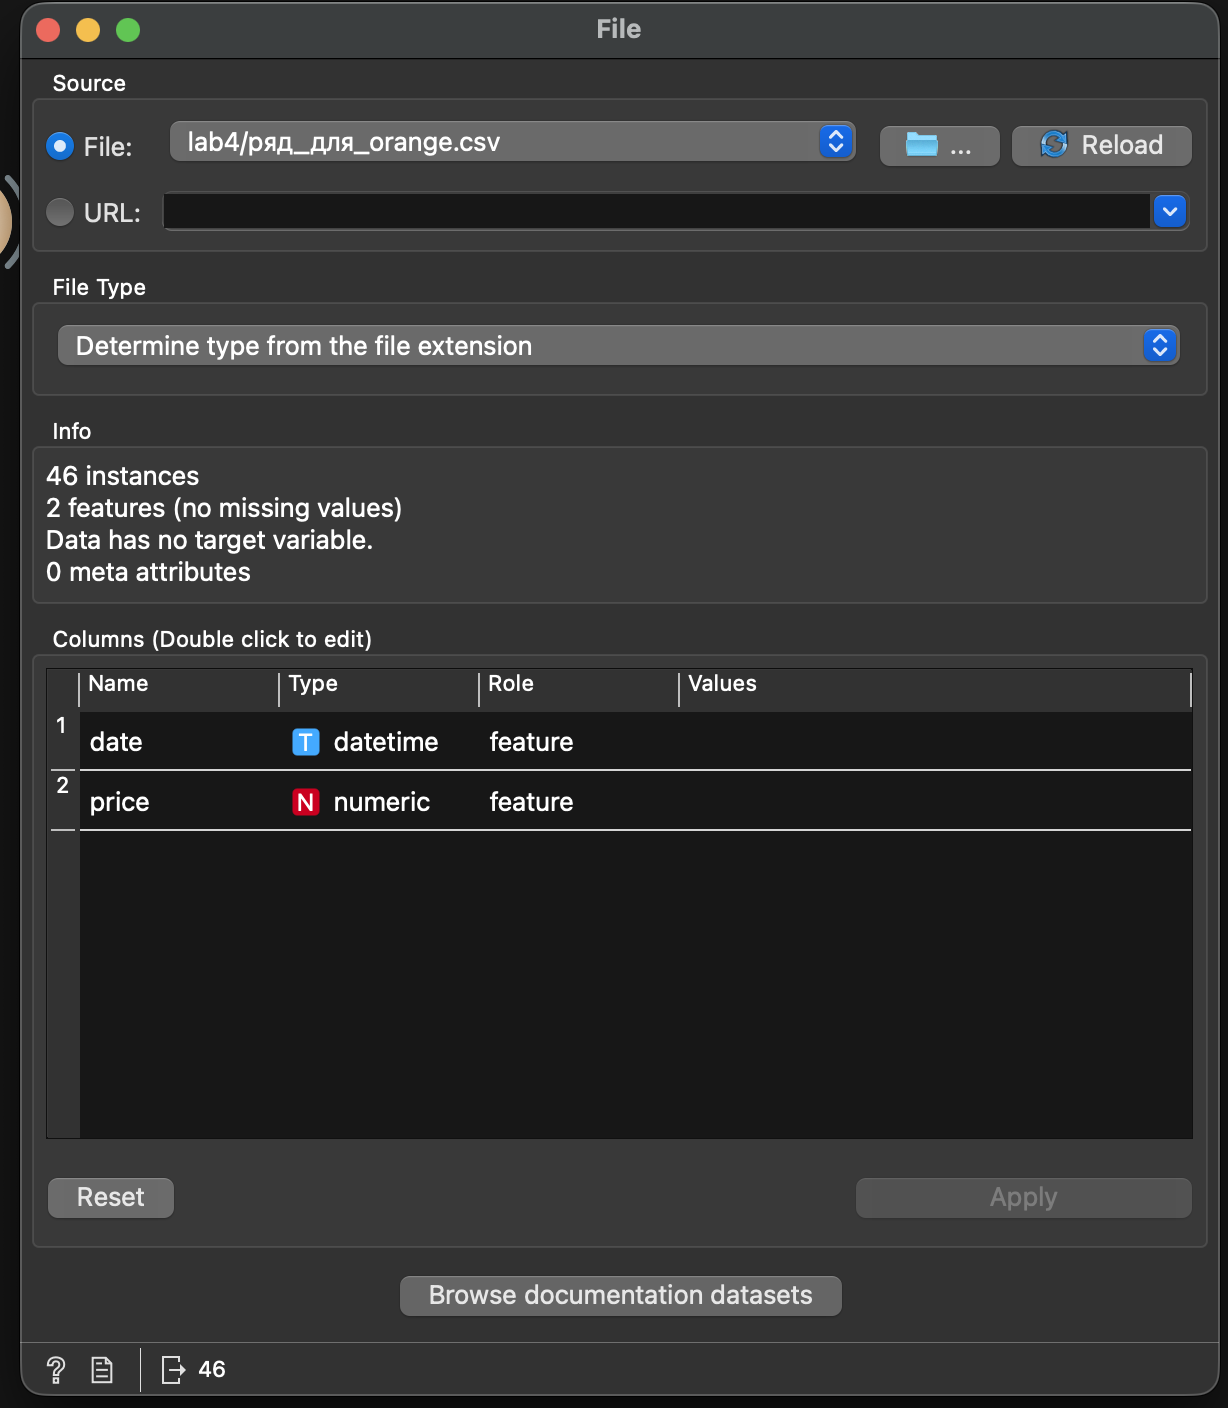

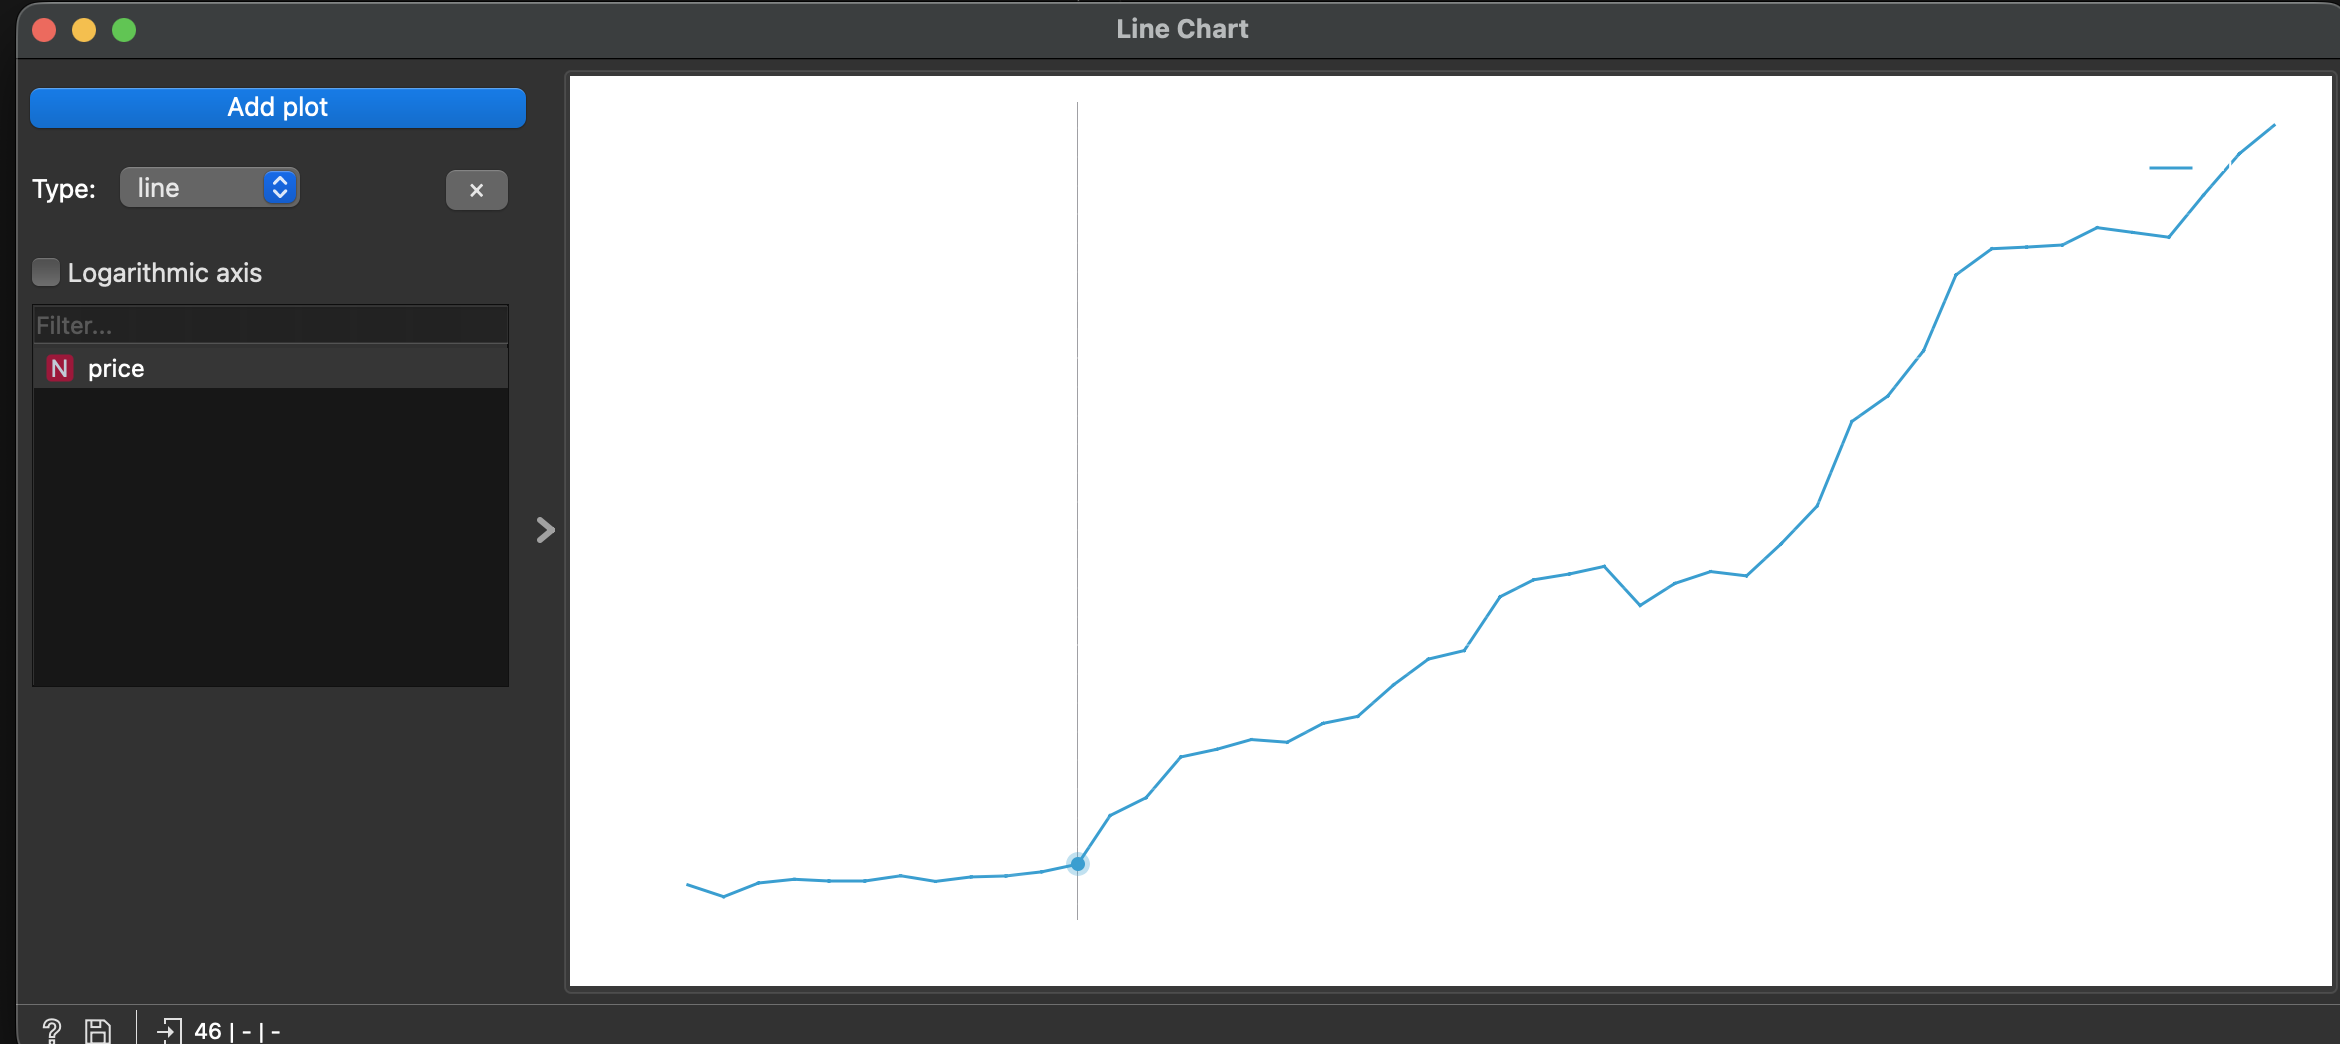

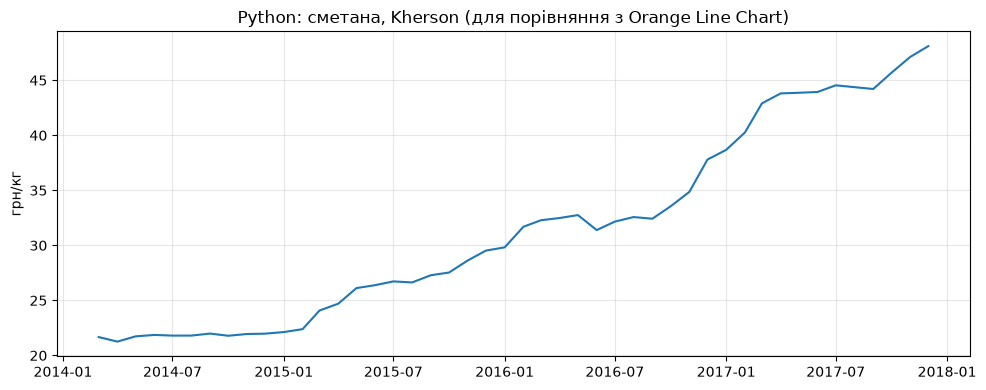

Контрольні точки: min = 21.25 (04.2014), max = 48.10 (12.2017), 06.2016 = 31.39


In [13]:
from IPython.display import Image, display

display(Image('orange_потік.png'))
display(Image('orange_file.png'))
display(Image('orange_line_chart.png'))

# графік із Python для порівняння
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(y_filled.index, y_filled.values, '-', color='tab:blue')
ax.set_title(f'Python: {GOOD_UA}, {MARKET} (для порівняння з Orange Line Chart)')
ax.set_ylabel('грн/кг'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f'Контрольні точки: min = {y_filled.min():.2f} ({y_filled.idxmin():%m.%Y}), '
      f'max = {y_filled.max():.2f} ({y_filled.idxmax():%m.%Y}), '
      f'06.2016 = {y_filled["2016-06-01"]:.2f}')

**Висновок до завдання 11:**

**Висновок до завдання 11:**

В Orange побудовано потік `File → Form Timeseries → Interpolate → Line Chart` (у поточній версії додатка Timeseries віджет As Timeseries має назву Form Timeseries).

У віджеті File завантажено файл `ряд_для_orange.csv`: 46 записів, 2 змінні, пропущених значень немає. Змінну `date` розпізнано як **datetime** (time), `price` — як **numeric**. У віджеті Form Timeseries змінну `date` обрано як часову, тож Orange трактує дані як впорядкований місячний ряд; на вході й на виході віджета по 46 записів. Віджет Interpolate пропусків не знайшов, бо пропуск 08.2017 заповнено ще в Python (завдання 2), тому дані на виході не змінилися.

Графік у Line Chart збігається з графіком 1 із завдання 3: та сама форма й ті самі характерні ділянки — майже рівний 2014 рік (≈21–22 грн) з мінімумом 21.25 грн у 04.2014, зростання з 03.2015, просідання в 06.2016 до 31.39 грн, найкрутіший підйом наприкінці 2016 — на початку 2017, плато в середині 2017 і зростання до максимуму 48.10 грн у 12.2017. Отже, Orange отримав точно ті самі дані, що й Python.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

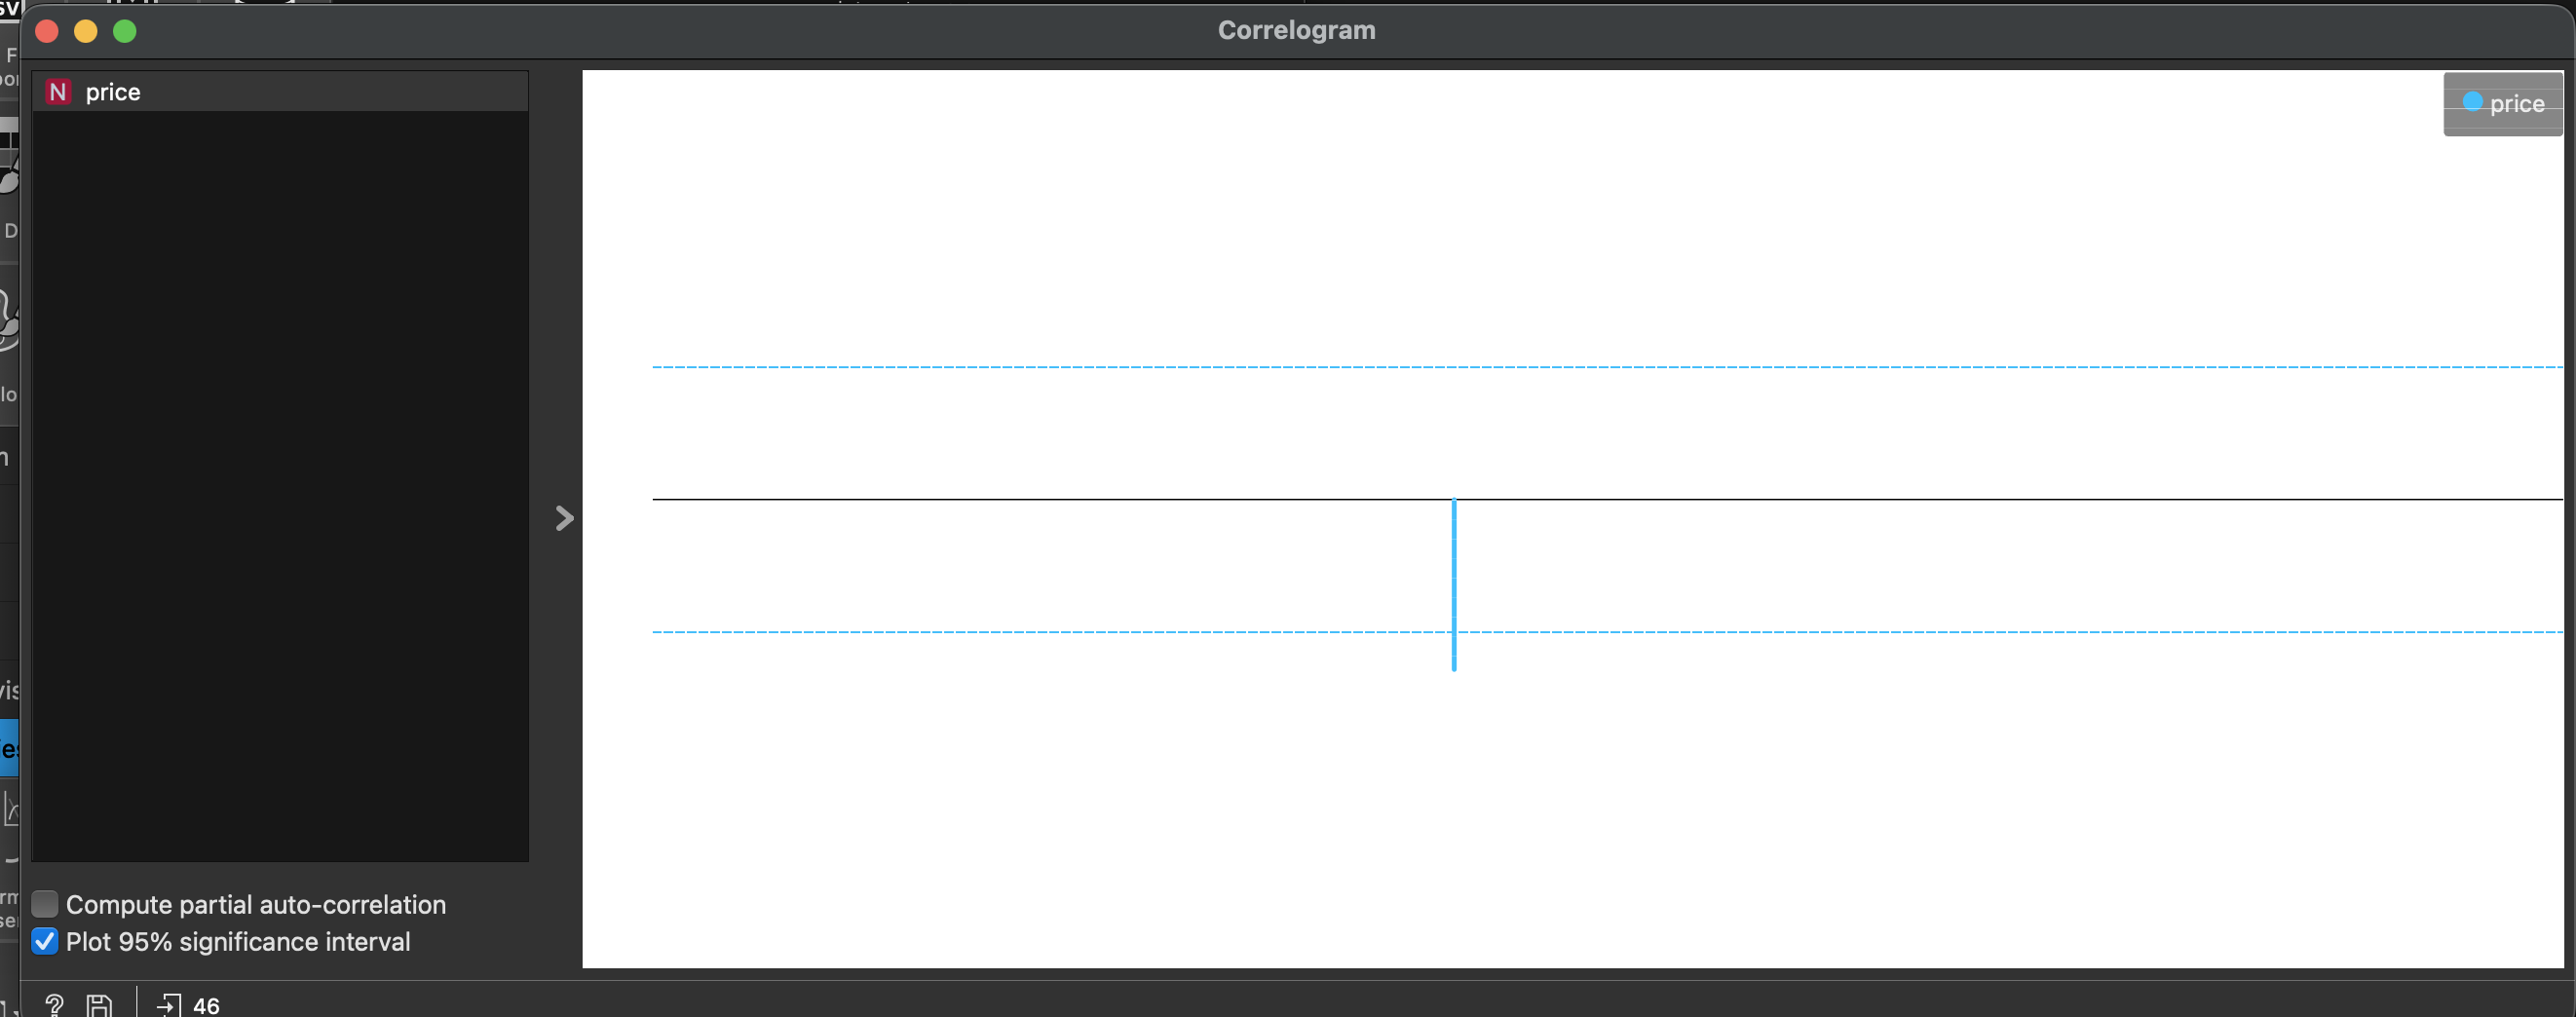

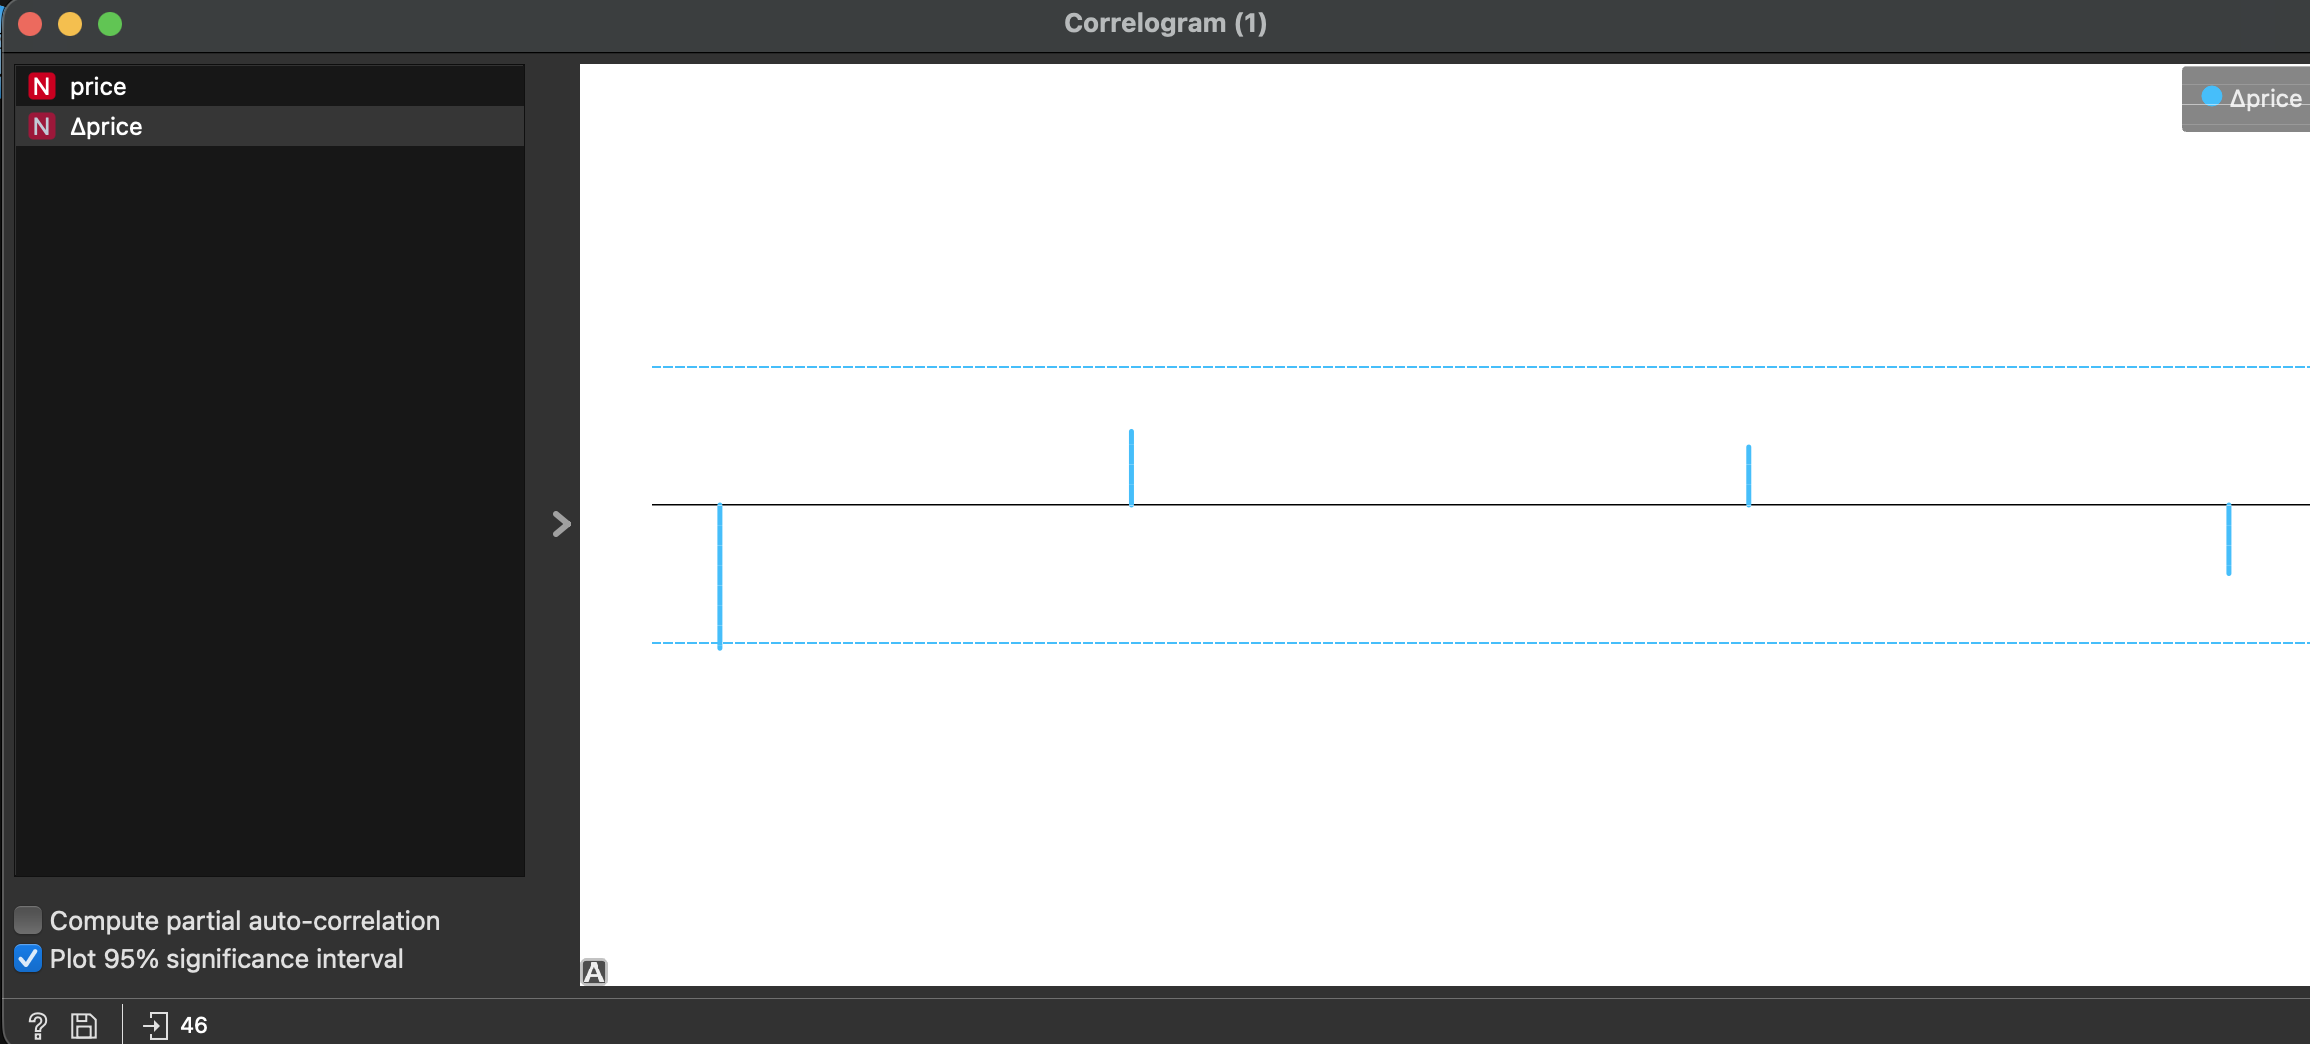

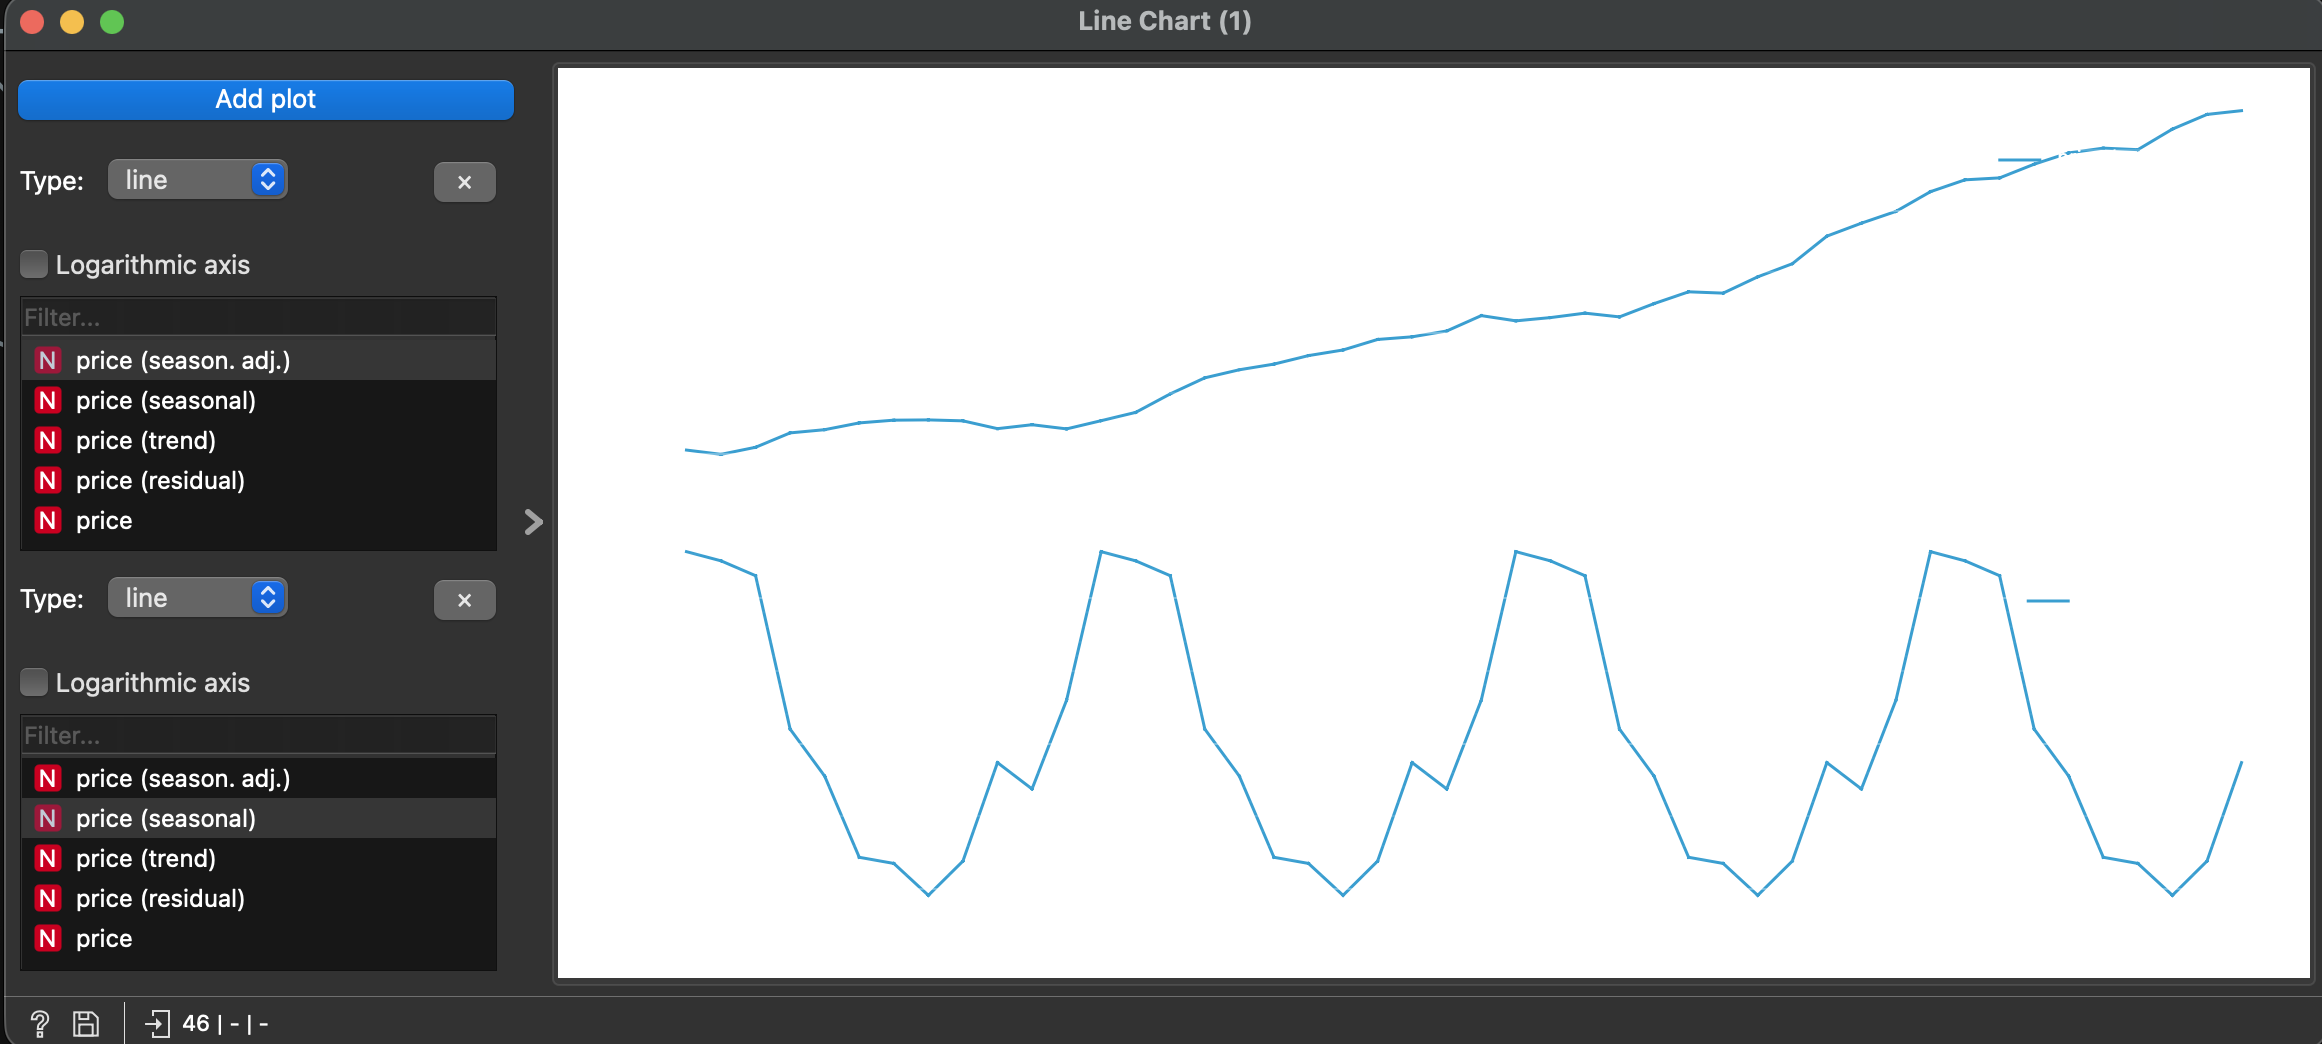

,ACF рівня,ACF різниці,значущий (різниця)
лаг,,,
1,0.94,0.30,так
2,0.87,0.21,
3,0.81,0.16,
4,0.75,-0.07,
5,0.68,-0.16,
6,0.61,-0.39,так
7,0.55,-0.13,
8,0.48,0.02,
9,0.40,-0.08,


Межа значущості ±0.29


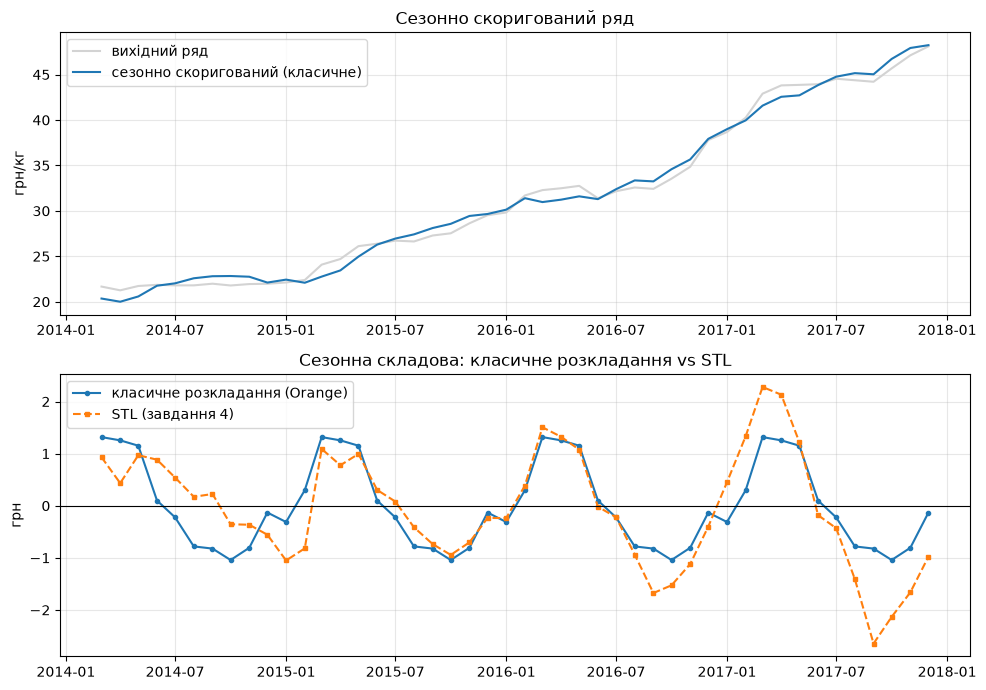

місяць,1,2,3,4,5,6,7,8,9,10,11,12
класичне,-0.31,0.3,1.32,1.25,1.15,0.10,-0.22,-0.78,-0.82,-1.04,-0.81,-0.13
STL,-0.28,0.3,1.45,1.17,1.06,0.25,-0.01,-0.65,-1.21,-1.24,-0.96,-0.54


Кореляція двох сезонних складових: 0.82
Розмах сезонної складової STL по роках:
date
2014    1.53
2015    2.14
2016    3.18
2017    4.92


In [14]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf

for f in ['orange_correlogram.png', 'orange_correlogram_diff.png', 'orange_seasonal.png']:
    display(Image(f))

# ── ACF для звірки з корелограмою Orange ──
acf_level = acf(y_filled, nlags=12)
acf_diff  = acf(y_diff,   nlags=12)
bound = 1.96 / np.sqrt(len(y_diff))
acf_tab = pd.DataFrame({'ACF рівня': acf_level[1:], 'ACF різниці': acf_diff[1:]},
                       index=range(1, 13)).round(2)
acf_tab['значущий (різниця)'] = np.where(acf_tab['ACF різниці'].abs() > bound, 'так', '')
acf_tab.index.name = 'лаг'
display(acf_tab)
print(f'Межа значущості ±{bound:.2f}')

# ── класичне розкладання (як у віджеті Seasonal Adjustment) vs STL ──
classic = seasonal_decompose(y_filled, model='additive', period=12)
y_adj = y_filled - classic.seasonal

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
axes[0].plot(y_filled.index, y_filled.values, color='lightgrey', label='вихідний ряд')
axes[0].plot(y_adj.index, y_adj.values, color='tab:blue', label='сезонно скоригований (класичне)')
axes[0].set_title('Сезонно скоригований ряд'); axes[0].set_ylabel('грн/кг')
axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(classic.seasonal.index, classic.seasonal.values, 'o-', ms=3,
             label='класичне розкладання (Orange)')
axes[1].plot(stl.seasonal.index, stl.seasonal.values, 's--', ms=3, label='STL (завдання 4)')
axes[1].axhline(0, color='black', lw=.8)
axes[1].set_title('Сезонна складова: класичне розкладання vs STL'); axes[1].set_ylabel('грн')
axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

comp_s = pd.DataFrame({
    'класичне': classic.seasonal.groupby(classic.seasonal.index.month).mean(),
    'STL':      stl.seasonal.groupby(stl.seasonal.index.month).mean(),
}).round(2)
comp_s.index.name = 'місяць'
display(comp_s.T)
print(f'Кореляція двох сезонних складових: {np.corrcoef(classic.seasonal, stl.seasonal)[0, 1]:.2f}')
print('Розмах сезонної складової STL по роках:')
print(stl.seasonal.groupby(stl.seasonal.index.year).agg(lambda s: s.max() - s.min()).round(2).to_string())

**Висновок до завдання 12:**

**Висновок до завдання 12:**

До потоку додано віджети Correlogram (для вихідного ряду й для першої різниці), Difference (порядок 1) і Seasonal Adjustment (період 12, адитивна модель).

**Корелограма вихідного ряду** в Orange має ту саму форму, що й ACF у завданні 5: автокореляція починається з 0.94 на лагу 1 і повільно спадає, залишаючись значущою до ≈9-го лагу. Це ознака нестаціонарного ряду з трендом.

**Корелограма першої різниці** також збігається з ACF із завдання 5: повільне спадання зникає, а за межу значущості (±0.29) виходять лише лаг 1 (0.30, на межі) і лаг 6 (−0.39); лаг 12 незначущий (0.23). **Висновки про значущі лаги в обох середовищах однакові**. Це очікувано, бо Orange і statsmodels рахують автокореляцію за однією формулою, а на вхід отримали ті самі 46 значень.

**Сезонна складова.** Віджет Seasonal Adjustment використовує класичне розкладання на основі ковзних середніх, а не STL. Попри це, сезонний профіль майже такий самий: обидва методи показують, що ціна вища за тренд у березні–травні (класичне розкладання: +1.15…+1.32 грн; STL: +1.06…+1.45 грн) і нижча у вересні–листопаді (класичне: −0.81…−1.04 грн; STL: −0.96…−1.24 грн). Кореляція двох сезонних складових — 0.82.

Відмінність між методами полягає в тому, що класичне розкладання дає **однаковий** сезонний малюнок щороку, а STL дозволяє сезонності змінюватися: у STL розмах сезонної складової зростає з ≈1.5 грн у 2014 році до ≈4.9 грн у 2017-му. Частина цього зростання пояснюється тим, що разом із ціною зростає й абсолютний розмір сезонних коливань, а частина — тим, що STL поглинає в сезонну складову великі стрибки 2016–2017 років.

**Сезонно скоригований ряд** майже не відрізняється від вихідного: сезонна поправка (≈ ±1.3 грн) мала порівняно з трендом (зростання з 22 до 48 грн). Це ще раз підтверджує висновок завдання 4: сезонність у ряді є, але вона помірна, а головна складова ряду — тренд.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

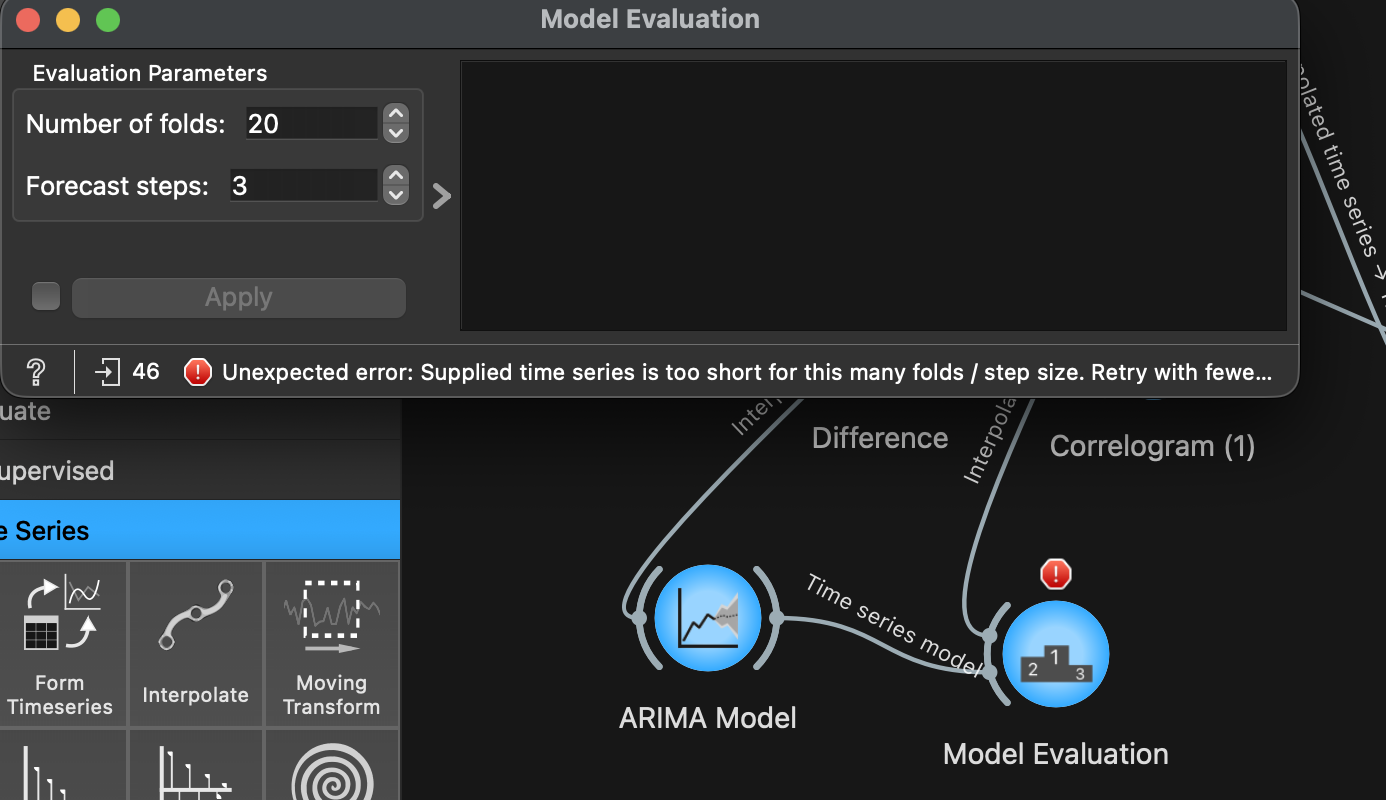

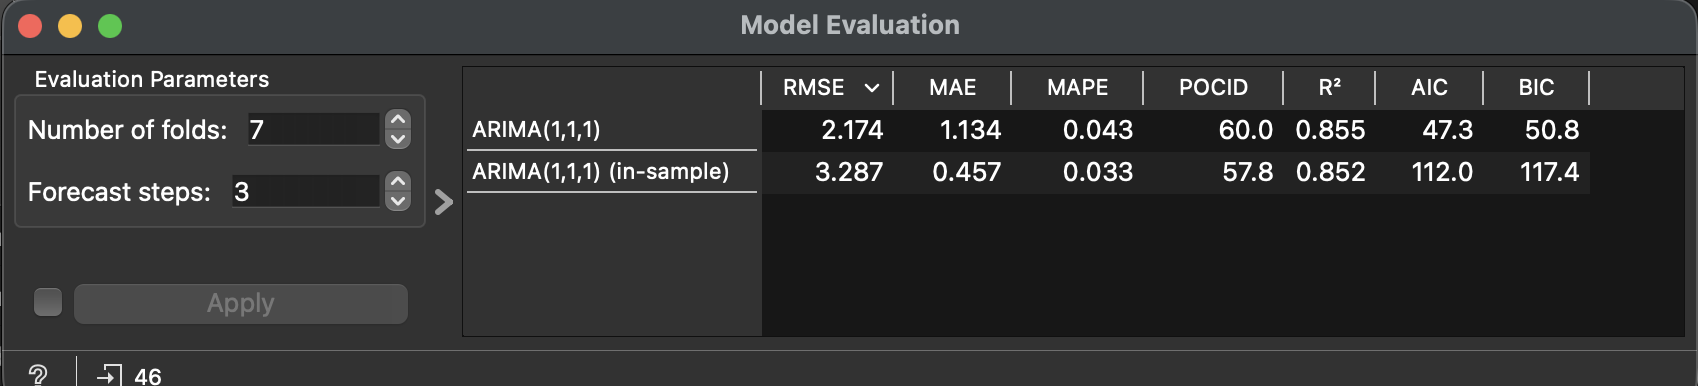

20 фолдів × 3 кроки: потрібно 20·3 + 1 = 61 точок, є 46 → ПОМИЛКА
 7 фолдів × 3 кроки: потрібно 7·3 + 1 = 22 точок, є 46 → OK
Максимально можлива кількість фолдів при 3 кроках: (46 − 1) // 3 = 15


,навчання,точок,тест
фолд Orange,,,
1,03.2014–09.2017,43,10.2017–12.2017
2,03.2014–06.2017,40,07.2017–09.2017
3,03.2014–03.2017,37,04.2017–06.2017
4,03.2014–12.2016,34,01.2017–03.2017
5,03.2014–09.2016,31,10.2016–12.2016
6,03.2014–06.2016,28,07.2016–09.2016
7,03.2014–03.2016,25,04.2016–06.2016


In [15]:
for f in ['orange_eval_error.png', 'orange_eval.png']:
    display(Image(f))

# ── чому 20 × 3 не працює: умова з вихідного коду Orange (functions.py) ──
#    if n_folds * forecast_steps + max_lag > len(data): raise ValueError(...)
p, d, q = 1, 1, 1
max_lag = max(p, d, q)
for folds_n, steps in [(20, 3), (7, 3)]:
    need = folds_n * steps + max_lag
    print(f'{folds_n:2d} фолдів × {steps} кроки: потрібно {folds_n}·{steps} + {max_lag} = {need} '
          f'точок, є {n} → {"ПОМИЛКА" if need > n else "OK"}')
print(f'Максимально можлива кількість фолдів при 3 кроках: ({n} − {max_lag}) // 3 = {(n - max_lag) // 3}')

# ── які саме 7 фолдів перевіряє Orange: train_end = −fold · steps ──
rows = []
for fold in range(1, 8):
    train_end = n - fold * 3
    rows.append([fold,
                 f'03.2014–{y_filled.index[train_end - 1]:%m.%Y}', train_end,
                 f'{y_filled.index[train_end]:%m.%Y}–{y_filled.index[train_end + 2]:%m.%Y}'])
orange_folds = pd.DataFrame(rows, columns=['фолд Orange', 'навчання', 'точок', 'тест']).set_index('фолд Orange')
display(orange_folds)

**Висновок до завдання 13:**

**Висновок до завдання 13:**

До потоку додано віджети ARIMA Model з порядком (1, 1, 1) і Model Evaluation. Для роботи Model Evaluation змінну `price` у віджеті File позначено як цільову (target).

**1. Результати** (Number of folds = 7, Forecast steps = 3) для ARIMA(1,1,1) на рухомому початку: RMSE = 2.174, MAE = 1.134, MAPE = 0.043, POCID = 60.0, R² = 0.855. Окремий рядок «(in-sample)» показує якість підгонки моделі на всьому ряді; він не є оцінкою прогнозу й для порівняння з Python не використовується.

Значення RMSE збігається з Python (2.174), а MAE і MAPE — ні (у Python MAE = 1.710, MAPE = 4.40 %). Розбіжність пояснено в завданні 14.

**2. Типові налаштування (20 фолдів × 3 кроки)** призводять до помилки: *«Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»* Причина — перевірка у вихідному коді Orange (`functions.py`): оцінювання можливе лише за умови, що кількість фолдів × кроки + максимальний порядок моделі не перевищує довжини ряду. Для ARIMA(1,1,1) максимальний порядок дорівнює 1, тож 20 × 3 вимагає 20·3 + 1 = 61 точку, а в ряді лише 46. Отже, це не збій, а наслідок короткого ряду: за горизонту 3 кроки максимально можлива кількість фолдів — (46 − 1) // 3 = 15. Налаштування 7 × 3 вимагає 22 точки й виконується.

**3. Які фолди перевіряє Orange.** У кожному фолді кінець навчальної частини задається як `train_end = −fold · steps`: фолд 1 навчається на перших 43 місяцях (03.2014–09.2017) і прогнозує 10–12.2017, фолд 2 — на 40 місяцях (до 06.2017) і прогнозує 07–09.2017, …, фолд 7 — на 25 місяцях (03.2014–03.2016) і прогнозує 04–06.2016. Навчальна частина щоразу починається з 03.2014 і розширюється, а тестові відрізки по 3 місяці не перетинаються й разом покривають останні 21 місяць ряду (04.2016–12.2017). Це **точно ті самі 7 відрізків**, що й у Python (завдання 6–7), лише пронумеровані у зворотному порядку: Orange іде від кінця ряду до початку, а Python — від початку до кінця. Модель теж та сама: віджет ARIMA Model всередині викликає ту саму функцію statsmodels `ARIMA`, що й Python. Отже, прогнози в обох середовищах однакові, і будь-яка різниця в метриках пояснюється лише формулами метрик.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# ── 1. прогнози ARIMA(1,1,1) у порядку Orange: fold = 1..7, train_end = −fold·3 ──
T_or, P_or = [], []
for fold in range(1, 8):
    train_end = n - fold * 3
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        P_or.extend(ARIMA(v[:train_end], order=(1, 1, 1)).fit().forecast(3))
    T_or.extend(v[train_end:train_end + 3])
T_or, P_or = np.array(T_or), np.array(P_or)
e = T_or - P_or

# ── 2. відтворення метрик Orange ──
orange_vals = {'RMSE': 2.174, 'MAE': 1.134, 'MAPE': 0.043, 'POCID': 60.0}   # з таблиці Model Evaluation
repro = {
    'RMSE':  np.sqrt(np.mean(e ** 2)),
    'MAE':   np.median(np.abs(e)),
    'MAPE':  np.mean(np.abs(e)) / np.mean(np.abs(T_or)),
    'POCID': 100 * np.mean(np.diff(T_or) * np.diff(P_or) > 0),
}
formulas = {
    'RMSE':  '√( Σ(yᵢ − ŷᵢ)² / n )',
    'MAE':   'median |yᵢ − ŷᵢ|',
    'MAPE':  'mean|yᵢ − ŷᵢ| / mean|yᵢ|',
    'POCID': '100 · частка i: (yᵢ₊₁ − yᵢ)(ŷᵢ₊₁ − ŷᵢ) > 0',
}
tab14 = pd.DataFrame({
    'Orange':             orange_vals,
    'відтворення Python': {k: round(x, 3) for k, x in repro.items()},
    'формула Orange':     formulas,
})
tab14['збіг до 3-го знака'] = [abs(tab14.loc[k, 'Orange'] - tab14.loc[k, 'відтворення Python']) < 0.0015
                               if k != 'POCID' else tab14.loc[k, 'Orange'] == tab14.loc[k, 'відтворення Python']
                               for k in tab14.index]
display(tab14)

# ── 3. порівняння з «класичними» означеннями з Частини 1 ──
classic = {
    'RMSE':  np.sqrt(np.mean(e ** 2)),
    'MAE':   np.mean(np.abs(e)),
    'MAPE':  np.mean(np.abs(e / T_or)) * 100,
}
cmp14 = pd.DataFrame({
    'Orange':                   [repro['RMSE'], repro['MAE'], repro['MAPE']],
    'Python, Частина 1':        [classic['RMSE'], classic['MAE'], classic['MAPE']],
    'класичне означення':       ['√mean(e²)', 'mean|e|', 'mean|e/y| · 100 %'],
}, index=['RMSE', 'MAE', 'MAPE']).round(3)
display(cmp14)
print(f'MAPE Orange у відсотках: {repro["MAPE"] * 100:.2f} % проти {classic["MAPE"]:.2f} % у Python')
print(f'Середня абсолютна похибка {classic["MAE"]:.3f} vs медіанна {repro["MAE"]:.3f}: '
      f'середня більша, бо кілька великих промахів тягнуть її вгору')
print('Найбільші абсолютні похибки:', np.sort(np.abs(e))[-4:].round(2))

,Orange,відтворення Python,формула Orange,збіг до 3-го знака
RMSE,2.174,2.174,√( Σ(yᵢ − ŷᵢ)² / n ),True
MAE,1.134,1.134,median |yᵢ − ŷᵢ|,True
MAPE,0.043,0.043,mean|yᵢ − ŷᵢ| / mean|yᵢ|,True
POCID,60.000,60.000,100 · частка i: (yᵢ₊₁ − yᵢ)(ŷᵢ₊₁ − ŷᵢ) > 0,True


,Orange,"Python, Частина 1",класичне означення
RMSE,2.174,2.174,√mean(e²)
MAE,1.134,1.710,mean|e|
MAPE,0.043,4.402,mean|e/y| · 100 %


MAPE Orange у відсотках: 4.34 % проти 4.40 % у Python
Середня абсолютна похибка 1.710 vs медіанна 1.134: середня більша, бо кілька великих промахів тягнуть її вгору
Найбільші абсолютні похибки: [2.97 3.84 3.94 5.07]


**Висновок до завдання 14:**

Модель ARIMA(1,1,1) і 7 фолдів по 3 кроки в обох середовищах однакові: віджет ARIMA Model всередині викликає ту саму функцію statsmodels, а відрізки навчання й тесту збігаються (завдання 13). Тому прогнози однакові, а розбіжності в метриках пояснюються лише їхніми формулами. Усі чотири метрики Orange відтворено в Python за формулами з вихідного коду додатка Timeseries (`functions.py`).

**1. Таблиця відтворення**

| Метрика | Orange | Відтворення в Python | Формула Orange |
|---|---|---|---|
| RMSE | 2.174 | 2.174 | √( Σ(yᵢ − ŷᵢ)² / n ) |
| MAE | 1.134 | 1.134 | median \|yᵢ − ŷᵢ\| |
| MAPE | 0.043 | 0.043 | mean\|yᵢ − ŷᵢ\| / mean\|yᵢ\| |
| POCID | 60.0 | 60.0 | 100 · частка пар сусідніх точок, де знаки змін факту й прогнозу збігаються |

Тут n = 21 — усі прогнози з 7 фолдів, склеєні в один список у порядку Orange (від останнього фолду до першого).

**2. Метрика, що не відповідає своїй назві, — MAE.** Абревіатура MAE зазвичай означає *Mean* Absolute Error — **середню** абсолютну похибку, а Orange рахує **медіану** абсолютних похибок (*Median* Absolute Error). Тому в Orange MAE = 1.134, а в Python — 1.710. Медіана менша за середнє, бо розподіл похибок асиметричний: більшість прогнозів помиляються на 0.5–1.5 грн, але кілька фолдів із різкими стрибками ціни дають похибки до 3–4 грн, які піднімають середнє, але майже не впливають на медіану.

Від загальноприйнятого означення відрізняється й **MAPE**. Класична MAPE — це середнє відносних похибок |eᵢ / yᵢ|, помножене на 100 %, а Orange ділить середню абсолютну похибку на середнє фактичне значення і не множить на 100. Тобто Orange фактично рахує зважену похибку (WAPE), записану частками одиниці: 0.043 = 4.34 % проти 4.40 % у Python. Через масштаб («0.043» замість «4.4 %») цю метрику легко помилково прочитати як похибку в 0.04 %.

**POCID** у Python не рахувалася. Важлива особливість її реалізації в Orange: різниці беруться по склеєному списку прогнозів, тож із 20 пар 6 припадають на стики фолдів (наприклад, грудень 2017 → липень 2017). Такі пари не відповідають жодній реальній зміні ціни в часі, і результат залежить від порядку склеювання фолдів: у хронологічному порядку POCID дала б 55 %, а не 60 %.

**3. Одразу збіглася RMSE** (2.174 в обох середовищах), бо Orange рахує її за стандартною формулою — корінь із середнього квадрата похибки, — тією самою, що й у Частині 1. Крім того, RMSE не залежить від порядку, у якому склеєно прогнози.

**4. Висновок.** Однакова назва метрики не гарантує однакової формули. Перш ніж порівнювати числа з двох інструментів, слід перевірити: (1) чи однакові вхідні дані; (2) чи однакові модель і її параметри; (3) чи однакова схема перевірки (кількість фолдів, горизонт, розширення вікна); (4) **точні формули метрик** — середнє чи медіана, частки чи відсотки, як агрегуються похибки з різних фолдів. Без цього розбіжність можна хибно пояснити «різними середовищами», хоча насправді різні означення метрик.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
# ті самі 20 пар, що й у POCID Orange (T_or, P_or із завдання 14)
d_true = np.diff(T_or)
d_pred = np.diff(P_or)

actual = np.where(d_true > 0, 'зросла', 'впала')
predicted = np.where(d_pred > 0, 'зросла', 'впала')

cm = pd.crosstab(pd.Series(actual, name='насправді'),
                 pd.Series(predicted, name='передбачила модель'))
cm = cm.reindex(index=['зросла', 'впала'], columns=['зросла', 'впала'], fill_value=0)
display(cm)

TP = cm.loc['зросла', 'зросла']; TN = cm.loc['впала', 'впала']
FN = cm.loc['зросла', 'впала'];  FP = cm.loc['впала', 'зросла']
total = cm.values.sum()
acc = (TP + TN) / total * 100

print(f'Пар усього: {total}')
print(f'Правильний напрямок: {TP} + {TN} = {TP + TN} → {acc:.1f} %   (POCID в Orange = 60.0)')
print(f'Збіг із POCID: {np.isclose(acc, 60.0)}')
print()
print(f'Частка «зросла» серед фактичних змін: {(TP + FN) / total * 100:.0f} % '
      f'→ правило «завжди зросте» дало б {(TP + FN) / total * 100:.0f} %')
print(f'Коли ціна справді росла, модель це вгадала в {TP}/{TP + FN} = {TP / (TP + FN) * 100:.0f} % випадків')
print(f'Коли ціна справді падала, модель це вгадала в {TN}/{TN + FP} = {TN / (TN + FP) * 100:.0f} % випадків')
print(f'Коли модель казала «зросте», вона мала рацію в {TP}/{TP + FP} = {TP / (TP + FP) * 100:.0f} % випадків')

# пари на стиках фолдів (не реальні зміни в часі)
boundary = np.array([(i + 1) % 3 == 0 for i in range(total)])
inside = (d_true * d_pred > 0)[~boundary]
print(f'\nПар на стиках фолдів: {boundary.sum()}; '
      f'POCID лише всередині фолдів: {inside.mean() * 100:.1f} % ({inside.sum()}/{len(inside)})')

передбачила модель,зросла,впала
насправді,,
зросла,8,3
впала,5,4


Пар усього: 20
Правильний напрямок: 8 + 4 = 12 → 60.0 %   (POCID в Orange = 60.0)
Збіг із POCID: True

Частка «зросла» серед фактичних змін: 55 % → правило «завжди зросте» дало б 55 %
Коли ціна справді росла, модель це вгадала в 8/11 = 73 % випадків
Коли ціна справді падала, модель це вгадала в 4/9 = 44 % випадків
Коли модель казала «зросте», вона мала рацію в 8/13 = 62 % випадків

Пар на стиках фолдів: 6; POCID лише всередині фолдів: 57.1 % (8/14)


**Висновок до завдання 15:**

**1. Матриця напрямку зміни** для ARIMA(1,1,1) побудована на тих самих 20 парах сусідніх точок, за якими Orange рахує POCID (21 прогноз із 7 фолдів, склеєних у порядку Orange):

| насправді \ передбачила модель | зросла | впала |
|---|---|---|
| **зросла** | 8 | 3 |
| **впала** | 5 | 4 |

**2. Перевірка.** Правильний напрямок модель передбачила в 8 + 4 = 12 випадках із 20, тобто 60 %. Це точно збігається зі значенням POCID = 60.0 в Orange. Отже, POCID — це частка правильних відповідей (accuracy) цієї матриці.

**3. Чи корисна модель для рішення «купувати зараз чи чекати».** Ні, практично не корисна. Ціна у вибірці росла в 11 випадках із 20 (55 %), тож найпростіше правило «ціна завжди зросте, купуй зараз» дає 55 % правильних відповідей, а модель — лише на 5 в. п. більше, тобто на одну пару з 20. Модель добре розпізнає зростання (вгадала 8 із 11 випадків, 73 %), але погано — падіння (4 із 9, 44 %). А саме падіння важливе для рішення «чекати». Коли модель каже «зросте», вона має рацію лише в 8 із 13 випадків (62 %). До того ж 6 із 20 пар припадають на стики фолдів (наприклад, грудень 2017 → липень 2017) і не відповідають реальним змінам ціни. Якщо їх відкинути, частка правильних напрямків падає до 57 % (8 із 14), тобто практично до рівня правила «завжди зросте». На 20 парах така різниця статистично не відрізняється від випадкової.

**Чому це інше питання, ніж MAE та RMSE.** MAE і RMSE вимірюють, **наскільки** прогноз далекий від факту в гривнях, і нічого не кажуть про напрямок. Модель може мати малу похибку, але систематично помилятися з напрямком (наприклад, прогноз 44.2 при факті 44.3 і попередньому значенні 44.5: похибка мізерна, але модель «бачить» інший рух). І навпаки, модель з великою похибкою може правильно вгадувати, куди рухається ціна. Для рішення «купувати чи чекати» важливий саме напрямок, тож оцінювати модель для цього завдання треба за матрицею напрямку (POCID, частка вгаданих падінь і зростань), а не лише за MAE та RMSE. Як і в класифікації, одна загальна accuracy тут вводить в оману: потрібно дивитися на кожну клітинку матриці й порівнювати з базовим правилом.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Проаналізовано ряд роздрібних цін на сметану на ринку Херсона (03.2014–12.2017, 46 місяців, один пропуск у 08.2017, заповнений лінійною інтерполяцією). Ряд має дуже сильний висхідний тренд: ціна зросла з 21.67 до 48.10 грн (F_T = 0.997), причому зростання почалося лише з 03.2015.

Сезонність у ряді є, але помірна: сила сезонності за STL F_S = 0.823 перевищує поріг 0.64, сезонний профіль (ціна вища за тренд у березні–травні й нижча у вересні–листопаді) підтверджується класичним розкладанням в Orange, а в ACF першої різниці й залишках ARIMA лишається значущий лаг 6. Водночас розмах сезонних коливань становить лише 5–10 % від рівня ціни, а лаг 12 в ACF незначущий.

Найкращим методом прогнозування за ретроспективною перевіркою з рухомим початком (7 фолдів × 3 кроки) виявився найпростіший базис — дрейф (MAE = 1.171 грн, MAPE = 2.96 %). ARIMA(1,1,1) йому програла (MAE = 1.710) і навіть не перевершила наївний прогноз, бо без константи не враховує тренду; найкраща модель ARIMA для цього ряду — випадкове блукання з дрейфом, що збігається з базисом «дрейф».

Сканування за t-статистикою виявило точку зміни рівня в 03.2017 (середнє 27.85 грн до і 44.85 грн після). Порівняння з рядами без зламу показало, що вона лише на межі значущості (p ≈ 0.04). Можливе зовнішнє пояснення — подвоєння мінімальної заробітної плати з 01.2017, після якого ціна за чотири місяці зросла на 23 %.

Однаково названі метрики в Python та Orange дали різні числа не через різні дані чи моделі — вони однакові, — а через різні формули. Orange рахує під назвою MAE медіану абсолютних похибок (1.134 проти 1.710), а MAPE — як відношення середньої похибки до середнього значення частками одиниці (0.043 проти 4.40 %); RMSE збіглася одразу, бо рахується за стандартною формулою. POCID = 60 % лише на 5 в. п. перевищує правило «ціна завжди зростає», тож для рішення «купувати чи чекати» модель практично не корисна.

Через те, що ряд має лише 46 спостережень (≈3.8 річних цикли), не вдалося надійно встановити, чи сезонність стабільна, а не породжена кількома великими стрибками 2015–2017 років. Так само не вдалося впевнено довести значущість точки зміни режиму, оцінити складніші моделі (сезонну ARIMA, AR(6)) без ризику перенавчання й отримати стійкі оцінки якості прогнозу: на 21 тестовій точці різниця між моделями в кілька десятих гривні може бути випадковою.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic), модель Claude Opus 5.5 |
| Для яких саме завдань | Завдання 1–15 і загальний висновок |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код для всіх завдань Частини 1 і для завдань 11–15; чернетки письмових висновків; пояснення понять (ACF/PACF, стаціонарність, тести ADF і KPSS, STL, ARIMA, рухомий початок, тест Льюнга–Бокса, t-тест Велча); покрокові інструкції для Orange; допомога у виправленні помилок під час налаштування Orange (тип змінної, цільова змінна) |
| Що ви змінили у згенерованому результаті й чому | Прибрано зайві методи, які не вимагались умовою (четвертий спосіб заповнення пропуску, кубічний сплайн, робастний STL), щоб відповідати завданню; висновки переписано в безособовій формі |
| Що з отриманого ви **перевірили самостійно** і яким способом | Усі числа у висновках звірено з виводом власного зошита після Restart & Run All; графік Line Chart в Orange порівняно з графіком із Python; метрики Model Evaluation в Orange звірено з відтворенням у Python до третього знака |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так: неправильно пояснено причину значення кубічного сплайна (насправді pandas за замовчуванням будує згладжувальний, а не інтерполяційний сплайн); хибно визначено значок типу datetime в Orange як текстовий |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________